# Mini-projet MP6 · Banc d'essai génératif : VAE contre GAN sur Fashion-MNIST — solution de référence (exécutée)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookIA/blob/main/projets/partie_6_generatif/solution/mp6_generatif.ipynb)

La solution de référence, exécutée en mode rapide avec `genbench/` de ce dossier et la librairie de référence. Les fichiers du mode complet (`config.json`, `results.json`, les figures du README) viennent d'une exécution de ce notebook avec `FAST_MODE = False`. Tes chiffres n'ont pas à être identiques : d'autres choix donnent d'autres valeurs, tout aussi justes s'ils sont bien mesurés. Le README de portfolio et la fiche modèle rédigés à partir de ces résultats sont dans ce dossier.

**Mode rapide et mode complet.** Avec `FAST_MODE = True` (la cellule de setup), les modèles s'entraînent sur des sous-ensembles (15 000 images pour le classifieur, 10 000 pour les générateurs, 3 à 5 epochs), et chaque mesure porte sur 2 000 images : le notebook tourne en 4 minutes environ sur un CPU à deux cœurs (3,6 min mesurées, CPU au repos). Le mode complet (les 50 000 images d'entraînement, 10 à 15 epochs, 10 000 images par mesure) se lance sur un GPU de Colab (🚀, *Exécution → Modifier le type d'exécution → GPU*) ; il a pris 48 minutes sur un CPU à deux cœurs, dont un quart d'heure pour les deux DCGAN de l'étape MP6.5. Ses fichiers (`config.json`, `results.json`, les figures du README) ne sont jamais écrasés par ceux du mode rapide, suffixés `_rapide`. Ferme les autres notebooks pendant qu'il tourne : les convolutions ralentissent beaucoup quand les cœurs sont partagés.

| Étape | Contenu | ⏱️ |
|---|---|---|
| MP6.1 | Cadrage : protocole d'évaluation écrit, data card relue, configuration et graines | 60 min |
| MP6.2 | Classifieur de référence Fashion-MNIST (features pour la distance de Fréchet, accuracy ≥ 90 %) | 60 min |
| MP6.3 | VAE convolutif : entraînement, réglage de β, courbes reconstruction/KL | 120 min |
| MP6.4 | DCGAN (option cGAN) : entraînement journalisé, checkpoints, reprise | 150 min |
| MP6.5 | Évaluation : distance de Fréchet sur 3 graines, classes générées, plus proches voisins | 90 min |
| MP6.6 | Galerie : grilles, interpolations sphériques, échantillons conditionnels | 45 min |
| MP6.7 | README, model card, tests pytest et nettoyage du dépôt | 75 min |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (CPU, a few minutes); False = full version
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookIA.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookIA")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WB_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wb").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wb").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier du workbook.")

os.environ["WB_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wb  # noqa: E402

cfg = wb.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mylearn = wb.load_mylearn("ref")  # reference implementation

🧪 Deep Learning Workbook : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | scikit-learn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cpu | torchvision 0.26.0+cpu
   Device : cpu | Graine : 42 | FAST_MODE : True


In [2]:
# The project folder of the reference solution
PROJECT_NAME = "partie_6_generatif"
PROJECT = ROOT / "projets" / PROJECT_NAME / "solution"
FIGURES = PROJECT / "figures"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
import data  # noqa: E402
import genbench  # noqa: E402

print("Dossier du projet :", PROJECT.relative_to(ROOT))

Dossier du projet : projets/partie_6_generatif/solution


In [3]:
# Tools of the notebook (run this cell)
import copy
import importlib
import json
import random
import re
import shutil
import tempfile
import time
from contextlib import contextmanager

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.ticker import MaxNLocator

from wb.nbtools import StopCheck, filled   # StopCheck: raised after a ❌ that makes the rest of a check cell meaningless

torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # 🚀 full mode: about 50 min on a 2-core CPU, less on a GPU
SUFFIX = "_rapide" if FAST_MODE else ""          # the files of the fast mode never overwrite those of the full mode
CONFIG_FILE = f"config{SUFFIX}.json"
RESULTS_FILE = f"results{SUFFIX}.json"
RUNS_DIR = PROJECT / "runs"                     # the checkpoints and logs of the GAN (heavy: not committed)
CLF_TARGET = 0.87 if FAST_MODE else 0.90         # the reference classifier, validation accuracy
SELECT_SEED = 100                                # the sampling seed of the choice of beta (MP6.3)
SAMPLE_SEED = 7                                  # the fixed noise of the grids (MP6.4, MP6.6)
N_NEIGHBORS = 2_000                              # MP6.5: samples whose nearest neighbours are searched
STARTED = time.perf_counter()

FAILED = {}         # check cell -> its guardrails that failed at its last run
_CURRENT = [None]
UNFINISHED = "la cellule s'est arrêtée avant la fin de ses vérifications (une erreur, ou une étape pas encore faite)"


def checks_of(cell):
    """Start the guardrails of one check cell: its failures of a previous run are forgotten. Until checks_done() runs,
    the cell counts as failed."""
    _CURRENT[0] = cell
    FAILED[cell] = [UNFINISHED]


def checks_done():
    """The current check cell ran to its end."""
    if _CURRENT[0] in FAILED and UNFINISHED in FAILED[_CURRENT[0]]:
        FAILED[_CURRENT[0]].remove(UNFINISHED)


def verdict(step, ok, success, failure):
    """Print ✅ with the success message, or ❌ with the failure message (remembered until the cell runs again)."""
    print(f"✅ {step} : {success}" if ok else f"❌ {step} : {failure}")
    if not ok and _CURRENT[0] is not None:
        FAILED[_CURRENT[0]].append(failure)
    return bool(ok)


def pending(step, message):
    """Print ⏳ with the message: a step not done yet."""
    print(f"⏳ {step} : {message}")
    if _CURRENT[0] is not None:
        FAILED[_CURRENT[0]].append(message)
    return False


PENDING = "⏳ pas encore écrit"   # the first words of a test failure on a function not written yet (conftest.py)


@contextmanager
def attempt(step):
    """wb.attempt (⏳ for what is not written yet), and any other error of your code as one ❌ line, so that « Run all »
    goes on (the guardrails of the cell stay failed)."""
    try:
        with wb.attempt(step):
            yield
    except StopCheck:
        pass
    except Exception as exc:
        verdict(step, False, "", f"ton code lève {type(exc).__name__}: {str(exc)[:300]} (la vérification de la cellule "
                "s'arrête là ; corrige, puis relance-la)")


def ready(*names):
    """True when the variables of the earlier steps exist; otherwise print which ones are missing."""
    missing = [name for name in names if name not in globals()]
    if missing:
        print(f"⏳ il manque {', '.join(missing)} : exécute d'abord les cellules des étapes précédentes, vérifications "
              "comprises (ce sont souvent elles qui créent ces variables).")
    return not missing


def kit_ok():
    """Import your latest saved genbench again (its modules, in order); False, with the reason, when it cannot be
    imported yet."""
    global genbench
    try:
        for name in ("genbench.models", "genbench.train", "genbench.evaluate"):
            module = sys.modules.get(name)
            importlib.reload(module) if module is not None else importlib.import_module(name)
        genbench = importlib.reload(sys.modules["genbench"]) if "genbench" in sys.modules else importlib.import_module("genbench")
    except Exception as exc:
        print(f"⚠️ genbench ne s'importe pas : {type(exc).__name__}: {exc}")
        return False
    return True


def save(fig, name):
    """Save a figure in the figures/ folder of the project: « name_rapide.png » in fast mode, so that the full-mode
    figure shown by the README stays."""
    FIGURES.mkdir(exist_ok=True)
    fig.savefig(FIGURES / name.replace(".png", f"{SUFFIX}.png"), dpi=110, bbox_inches="tight")


def show_grid(ax, images, nrow, title=None):
    """Draw images (N, 1, 28, 28) in [0, 1] on a grid of nrow per row (genbench.image_grid)."""
    ax.imshow(genbench.image_grid(images, nrow), cmap="gray", vmin=0, vmax=1)
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def thousands(n):
    """An integer with a space between the thousands (12 345)."""
    return f"{n:,}".replace(",", " ")


def fr(x, digits=1):
    """A number written the French way (decimal comma)."""
    return f"{x:.{digits}f}".replace(".", ",")


def weight_gap(model_1, model_2):
    """The largest absolute gap between the floating-point tensors of two state_dicts."""
    return max((a - b).abs().max().item() for a, b in zip(model_1.state_dict().values(), model_2.state_dict().values())
               if a.is_floating_point())


def run_project_tests(extra=(), env=None, quiet=False):
    """Run the tests of the project folder (test_genbench.py) and print the failures (⏳ for a function not written
    yet); return (passed, failed, reasons), reasons being the first line of each failure."""
    command = [sys.executable, "-m", "pytest", str(PROJECT / "test_genbench.py"), "-q", "-p", "no:cacheprovider",
               "--color=no", "-rfE", "--tb=no", *extra]
    result = subprocess.run(command, cwd=ROOT, capture_output=True, text=True,
                            env={**os.environ, "COLUMNS": "1000", **(env or {})})
    lines = result.stdout.strip().splitlines()
    failures = [line for line in lines if line.startswith(("FAILED ", "ERROR "))]
    if not quiet:
        for line in failures[:8]:
            kind, _, rest = line.partition(" ")
            name, _, reason = rest.partition(" - ")
            where = " (erreur hors du test : import, fixture…)" if kind == "ERROR" else ""
            mark = "⏳" if reason.startswith(PENDING) else "❌"
            print(f"{mark} {name.split('::')[-1]}{where}" + (f"\n   {reason[:600]}" if reason else ""))
    summary = lines[-1] if lines else result.stderr.strip()[-300:]
    passed = sum(int(n) for n in re.findall(r"(\d+) passed", summary))
    failed = sum(int(n) for n in re.findall(r"(\d+) (?:failed|error)", summary))
    if not quiet:
        print("pytest:", summary)
    return passed, failed, [line.partition(" - ")[2] for line in failures]


MUTANTS = {   # name -> (what the mutant breaks, its module, its function, the code of the wrong version, given `orig`)
    "vae_loss": ("vae_loss moyenne la reconstruction sur les pixels au lieu de la sommer", "genbench.train", "vae_loss",
                 "def bad(logits, x, mu, log_var, beta=1.0):\n"
                 "    _, rec, kl = orig(logits, x, mu, log_var, beta)\n"
                 "    rec = rec / x[0].numel()\n"
                 "    return rec + beta * kl, rec, kl"),
    "gan_step": ("gan_step entraîne G avec le label « faux » : il apprend à être repéré", "genbench.train", "gan_step",
                 "def bad(G, D, opt_g, opt_d, real, z, labels=None, fake_labels=None):\n"
                 "    fake = G(z) if fake_labels is None else G(z, fake_labels)\n"
                 "    judge = lambda x, y: D(x) if y is None else D(x, y)\n"
                 "    a, b = judge(real, labels), judge(fake.detach(), fake_labels)\n"
                 "    loss_d = F.binary_cross_entropy_with_logits(a, torch.ones_like(a)) + F.binary_cross_entropy_with_logits(b, torch.zeros_like(b))\n"
                 "    opt_d.zero_grad()\n"
                 "    loss_d.backward()\n"
                 "    opt_d.step()\n"
                 "    c = judge(fake, fake_labels)\n"
                 "    loss_g = F.binary_cross_entropy_with_logits(c, torch.zeros_like(c))\n"
                 "    opt_g.zero_grad()\n"
                 "    loss_g.backward()\n"
                 "    opt_g.step()\n"
                 "    return {'loss_d': loss_d.item(), 'loss_g': loss_g.item(), 'd_real': torch.sigmoid(a).mean().item(), "
                 "'d_fake': torch.sigmoid(b).mean().item()}"),
    "features": ("classifier_features laisse le classifieur en mode entraînement (batchnorm et dropout)",
                 "genbench.evaluate", "classifier_features",
                 "def bad(model, images, batch_size=500):\n"
                 "    model.train()\n"
                 "    with torch.no_grad():\n"
                 "        out = [model.features(images[i:i + batch_size]) for i in range(0, len(images), batch_size)]\n"
                 "    return torch.cat(out).double().numpy()"),
    "neighbors": ("nearest_neighbors rend les distances au carré", "genbench.evaluate", "nearest_neighbors",
                  "def bad(queries, references, batch_size=1000):\n"
                  "    distances, indices = orig(queries, references, batch_size)\n"
                  "    return distances ** 2, indices"),
    "resume": ("load_checkpoint ne restaure pas l'état du générateur aléatoire : la reprise tire d'autres mini-batches",
               "genbench.train", "load_checkpoint",
               "def bad(path, G, D, opt_g, opt_d, generator):\n"
               "    kept = generator.get_state()\n"
               "    out = orig(path, G, D, opt_g, opt_d, generator)\n"
               "    generator.set_state(kept)\n"
               "    return out"),
}


def mutant_plugin(folder, name):
    """A pytest plugin that swaps one function of genbench for its mutant once the tests are collected: in its module,
    and wherever a module (the package, the test file) holds the original function under a name."""
    _, module, function, source = MUTANTS[name]
    body = source.replace("\n", "\n    ")
    (folder / f"mutant_{name}.py").write_text(
        "import sys\n\nimport numpy as np\nimport torch\nimport torch.nn.functional as F\n\n\n"
        "def pytest_collection_modifyitems(session, config, items):\n"
        f"    import {module}\n"
        f"    orig = sys.modules['{module}'].{function}\n"
        f"    {body}\n"
        "    for mod in list(sys.modules.values()):\n"
        "        for key, value in list(vars(mod).items()) if hasattr(mod, '__dict__') else []:\n"
        "            if value is orig:\n"
        "                setattr(mod, key, bad)\n", encoding="utf-8")


def check_document(step, path, sections, whole=True):
    """Guardrails of a Markdown deliverable: it exists, has its sections (French or English), and no TODO left
    (whole=False: only the sections given). What is still the template (a section or a paragraph that starts with
    TODO) is ⏳, not ❌."""
    text = path.read_text(encoding="utf-8") if path.exists() else ""
    if not verdict(step, bool(text), f"{path.name} existe.", f"il manque {path.name} dans le dossier du projet."):
        return ""
    todo_line = r"(?m)^\W*TODO\b"
    parts = re.split(r"(?m)^(#{2,}\s+.*)$", text)                # text, header, body, header, body…
    bodies = [(parts[i].lstrip("#").strip().lower(), parts[i + 1]) for i in range(1, len(parts) - 1, 2)]
    for section, keywords in sections.items():
        found = [body for header, body in bodies if any(word in header for word in keywords)]
        if not found:
            verdict(step, False, "", f"{path.name} : il manque une section « ## {section} » (ou en anglais, "
                    f"« ## {keywords[-1].capitalize()}… »).")
        elif any(re.search(todo_line, body) for body in found):
            pending(step, f"{path.name} : la section « {section} » est encore celle du modèle (TODO).")
        else:
            verdict(step, True, f"{path.name} : section « {section} ».", "")
    if whole:
        todo = re.findall(todo_line, text)
        if todo:
            pending(step, f"{path.name} : {len(todo)} paragraphe(s) commencent encore par « TODO » : remplace-les par ton texte.")
        else:
            verdict(step, True, f"{path.name} : plus aucun paragraphe « TODO ».", "")
    return text

## MP6.1 · Cadrage : protocole d'évaluation écrit, data card relue, configuration et graines ⏱️ 60 min

**Objectif :** fixer **avant** toute expérience ce que tu mesureras et comment, pour que les résultats ne puissent pas choisir eux-mêmes la façon dont on les juge.

a) **Lis le cahier des charges** (`projets/partie_6_generatif/README.md`) et la data card de Fashion-MNIST (`data/cards/fashion_mnist.md`). Écris ensuite, dans ton `README.md`, les sections « L'objectif » et « Le protocole d'évaluation » : les quatre mesures (distance de Fréchet sur les features du classifieur de référence, classes prédites des échantillons, plus proches voisins dans l'entraînement, inspection visuelle), les images réelles de comparaison (la validation), le nombre d'images générées, les graines, la règle de choix de β et la règle de mémorisation. Commite ce README avant de lancer la suite : la date du commit prouve que le protocole précède les résultats.
b) Dans `genbench/train.py`, écris `set_seed` et `save_config` (leurs docstrings).
c) Complète `CONFIG` dans la cellule suivante : trois graines d'entraînement, le nombre d'images générées par modèle et par graine (`n_eval`), les valeurs de β à comparer et la règle de mémorisation (`copy_quantile`). Les tailles des modèles et des entraînements sont proposées (elles dépendent de `FAST_MODE`) : tu peux les changer, mais **avant** les expériences. La vérification écrit la configuration dans `config_rapide.json` (mode rapide) ou `config.json` (mode complet), puis montre des images de chaque classe.

In [4]:
CONFIG = {
    "seeds": [0, 1, 2],                           # three training seeds per generator
    "n_eval": 2_000 if FAST_MODE else 10_000,     # generated images per model and seed (and as many real ones)
    "betas": [0.5, 1.0, 4.0],                     # the values of beta compared in MP6.3
    "copy_quantile": 0.01,                        # the rule of memorization (README, « Le protocole d'évaluation »)
    "classifier": {"width": 16, "n_features": 128, "n_train": 15_000 if FAST_MODE else 50_000,
                   "epochs": 3 if FAST_MODE else 10, "lr": 1e-3, "batch_size": 128},
    "vae": {"latent_dim": 16, "width": 32, "n_train": 10_000 if FAST_MODE else 50_000,
            "epochs": 5 if FAST_MODE else 15, "lr": 1e-3, "batch_size": 128},
    "gan": {"latent_dim": 64, "width": 32 if FAST_MODE else 48, "n_train": 10_000 if FAST_MODE else 50_000,
            "epochs": 5 if FAST_MODE else 10, "lr": 2e-4, "batch_size": 64, "conditional": True},
}

✅ MP6.1 : le package genbench a ses quatre fichiers.
versions : {'python': '3.13.18', 'numpy': '2.1.3', 'torch': '2.11.0+cpu'} · device : cpu


entraînement (50000, 28, 28), validation (10000, 28, 28) ; images de validation par classe : [956, 988, 1027, 1029, 975, 1026, 995, 958, 1022, 1024]
✅ MP6.1 : set_seed : random, NumPy et PyTorch rejouent les mêmes tirages.
✅ MP6.1 : save_config : la configuration, la date et les versions, relues telles quelles du fichier JSON.
✅ MP6.1 : save_config refuse une clé « date » (ValueError) et un objet non JSON (TypeError), sans écrire de fichier.
✅ MP6.1 : CONFIG : graines [0, 1, 2], 2 000 images par mesure, β parmi [0.5, 1.0, 4.0], copies sous le quantile 0.01.
💾 config_rapide.json écrit (2026-10-31).
✅ MP6.1 : README.md existe.
✅ MP6.1 : README.md : section « L'objectif ».
✅ MP6.1 : README.md : section « Le protocole d'évaluation ».


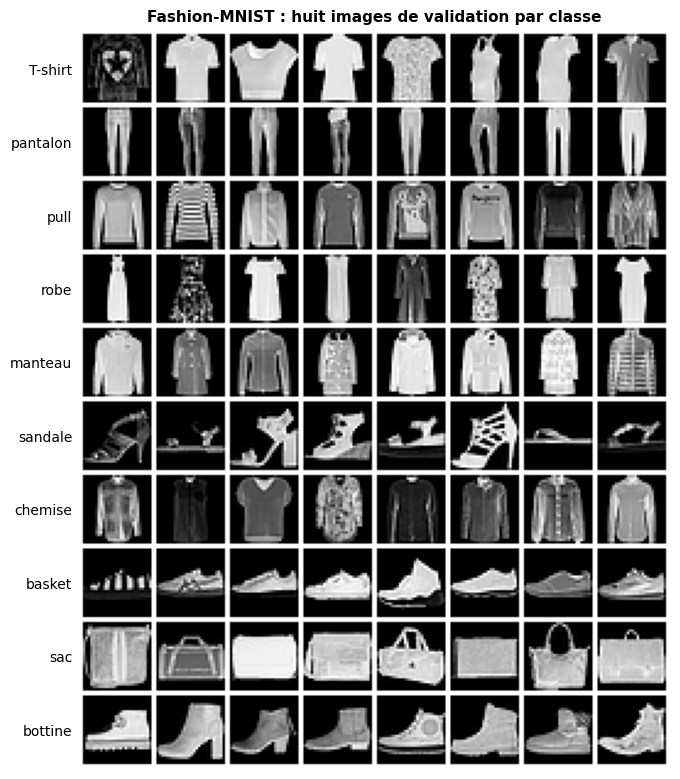

In [5]:
checks_of("MP6.1")
if kit_ok():
    files = ["__init__.py", "models.py", "train.py", "evaluate.py"]
    missing = [name for name in files if not (PROJECT / "genbench" / name).exists()]
    verdict("MP6.1", not missing, "le package genbench a ses quatre fichiers.", f"il manque genbench/{', genbench/'.join(missing)}.")
    print("versions :", genbench.library_versions(), "· device :", DEVICE)
    X_train, y_train, X_val, y_val = data.load_split()
    X_train_t, X_val_t = genbench.images_to_tensor(X_train).to(DEVICE), genbench.images_to_tensor(X_val).to(DEVICE)
    y_train_t, y_val_t = torch.from_numpy(y_train).to(DEVICE), torch.from_numpy(y_val).to(DEVICE)
    print(f"entraînement {X_train.shape}, validation {X_val.shape} ; images de validation par classe : "
          f"{np.bincount(y_val).tolist()}")
    with attempt("MP6.1"):
        genbench.set_seed(123)
        first = (random.random(), float(np.random.rand()), torch.rand(1).item())
        genbench.set_seed(123)
        again = (random.random(), float(np.random.rand()), torch.rand(1).item())
        verdict("MP6.1", first == again, "set_seed : random, NumPy et PyTorch rejouent les mêmes tirages.",
                "set_seed(seed) doit fixer les trois générateurs (random.seed, np.random.seed, torch.manual_seed) : "
                f"deux appels de même graine donnent {first} puis {again}.")
        folder_c = Path(tempfile.mkdtemp())
        written = genbench.save_config(folder_c / "c.json", {"a": [1, 2]})
        reread = json.loads((folder_c / "c.json").read_text(encoding="utf-8"))
        verdict("MP6.1", isinstance(written, dict) and reread == written and reread.get("a") == [1, 2]
                and {"date", "versions"} <= set(reread) and bool(re.fullmatch(r"\d{4}-\d{2}-\d{2}", str(reread.get("date")))),
                "save_config : la configuration, la date et les versions, relues telles quelles du fichier JSON.",
                "save_config(path, config) doit écrire un JSON qui contient les clés de config, « date » (AAAA-MM-JJ) et « versions », "
                f"et rendre ce contenu (relu : {reread}).")
        refused = []
        for bad_config, error in (({"date": "hier"}, ValueError), ({"model": object()}, TypeError)):
            try:
                genbench.save_config(folder_c / "bad.json", bad_config)
                refused.append(False)
            except error:
                refused.append(not (folder_c / "bad.json").exists())
        verdict("MP6.1", all(refused), "save_config refuse une clé « date » (ValueError) et un objet non JSON (TypeError), "
                "sans écrire de fichier.",
                "save_config doit lever ValueError pour une clé « date » ou « versions » déjà présente, et TypeError pour "
                "une valeur non JSON, sans écrire de fichier (json.dumps d'abord, write_text ensuite).")
    if filled(CONFIG) and filled(*[CONFIG.get(key) for key in ("seeds", "n_eval", "betas", "copy_quantile")]):
        seeds, betas = CONFIG["seeds"], CONFIG["betas"]
        problems = []
        if not (isinstance(seeds, list) and len(seeds) == 3 and len(set(seeds)) == 3 and all(isinstance(s, int) for s in seeds)):
            problems.append(f"seeds doit être une liste de trois entiers différents (reçu {seeds!r})")
        if not (isinstance(CONFIG["n_eval"], int) and 1_000 <= CONFIG["n_eval"] <= len(X_val)):
            problems.append(f"n_eval doit être un entier de 1 000 à {thousands(len(X_val))} (reçu {CONFIG['n_eval']!r})")
        if not (isinstance(betas, list) and len(betas) >= 3 and 1.0 in betas and all(b > 0 for b in betas)):
            problems.append(f"betas doit être une liste d'au moins trois valeurs positives, dont 1.0 (reçu {betas!r})")
        if not (isinstance(CONFIG["copy_quantile"], float) and 0 < CONFIG["copy_quantile"] <= 0.1):
            problems.append(f"copy_quantile doit être une part entre 0 et 0,1 (reçu {CONFIG['copy_quantile']!r})")
        if verdict("MP6.1", not problems, f"CONFIG : graines {seeds}, {thousands(CONFIG['n_eval'])} images par mesure, "
                   f"β parmi {betas}, copies sous le quantile {CONFIG['copy_quantile']}.", " ; ".join(problems) + "."):
            with attempt("MP6.1"):
                CONFIG_SAVED = genbench.save_config(PROJECT / CONFIG_FILE, {**CONFIG, "fast_mode": FAST_MODE,
                                                                           "split_seed": data.SPLIT_SEED})
                print(f"💾 {CONFIG_FILE} écrit ({CONFIG_SAVED['date']}).")
    else:
        pending("MP6.1", "CONFIG n'est pas encore rempli (la cellule précédente : seeds, n_eval, betas, copy_quantile).")
    check_document("MP6.1", PROJECT / "README.md", {"L'objectif": ["objectif", "goal"],
                                                    "Le protocole d'évaluation": ["protocole", "protocol"]}, whole=False)
    fig, ax = plt.subplots(figsize=(9, 9.6))
    picks = torch.cat([X_val_t[torch.where(y_val_t == k)[0][:8]] for k in range(10)])
    show_grid(ax, picks.cpu(), 8)
    for k, name in enumerate(data.CLASSES_FR):
        ax.text(-3, 2 + 30 * k + 14, name, ha="right", va="center", fontsize=10)
    ax.set_title("Fashion-MNIST : huit images de validation par classe", fontsize=11)
    save(fig, "donnees.png")
    plt.show()
checks_done()

✍️ **Observations (MP6.1)**

- **Le protocole** : les features (128 valeurs) d'un petit CNN entraîné sur les 50 000 images d'entraînement ; la distance de Fréchet entre `n_eval` images générées et autant d'images de validation (2 000 en mode rapide, 10 000 en mode complet), à côté du plancher de deux échantillons réels ; trois graines d'entraînement (0, 1, 2) par générateur, avec la moyenne et l'écart-type ; les classes prédites des échantillons (entropie normalisée, plus grande part) ; une quasi-copie est un échantillon plus proche de l'entraînement que 99 % des images de validation (`copy_quantile` = 0,01) ; β choisi sur la graine 0 par la plus petite distance, avec une graine de tirage réservée (`SELECT_SEED`), sans perdre plus de la moitié des latents.
- **La data card** : des photos de catalogue Zalando, centrées sur fond neutre, réduites en 28 × 28, sous licence MIT ; aucune personne. Les générateurs n'apprennent donc que des vignettes de catalogue : ils ne disent rien de vêtements portés ou photographiés dans la rue, et leurs images ne doivent pas passer pour des photos de produits réels. Les classes sont presque équilibrées (956 à 1 029 images de validation par classe), et la classe « chemise » chevauche T-shirt, pull et manteau : le classifieur s'y trompera, et l'histogramme des classes générées aussi.

## MP6.2 · Classifieur de référence Fashion-MNIST (features pour la distance de Fréchet, accuracy ≥ 90 %) ⏱️ 60 min

**Objectif :** construire l'instrument de mesure du banc d'essai, et vérifier qu'il mesure quelque chose avant de s'en servir.

Un générateur se juge en comparant ses images à de vraies images, non pas pixel par pixel, mais dans l'espace des **features** d'un réseau qui sait reconnaître des vêtements : c'est l'idée du FID (ch. 27), avec ici un petit CNN entraîné sur Fashion-MNIST à la place d'Inception. Dans `genbench/models.py`, écris les méthodes `features` et `forward` de `Classifier` (son `__init__` est donné) ; dans `genbench/train.py`, `train_classifier` ; dans `genbench/evaluate.py`, `classifier_features`, `predict_proba` et `accuracy` (leurs docstrings).

La cellule suivante entraîne le classifieur sur les images d'entraînement, mesure son accuracy de validation (au moins 90 % en mode complet ; le mode rapide, avec 15 000 images et 3 epochs, vise 87 %), puis calcule trois repères de la distance de Fréchet : entre deux échantillons d'images réelles (le **plancher**, ce que vaudrait un générateur parfait), et entre les vraies images de validation et des images d'entraînement floutées ou bruitées. Un instrument qui ne verrait pas le flou ne servirait à rien pour juger un VAE.

In [6]:
checks_of("MP6.2")
if kit_ok() and ready("X_train_t"):
    with attempt("MP6.2"):
        torch.manual_seed(0)
        probe = genbench.Classifier()
        x_p = X_val_t[:64].cpu()
        verdict("MP6.2", genbench.n_parameters(probe) == 218_586, "Classifier() : 218 586 paramètres.",
                f"Classifier() a {genbench.n_parameters(probe)} paramètres, attendu 218 586 : n'ajoute pas de couche, "
                "son __init__ est donné.")
        with torch.no_grad():
            probe.train()(x_p)                                   # running statistics that are no longer the initial ones
        probe.eval()
        with torch.no_grad():
            want_f = probe.to_features(probe.body(x_p))
            want_l = probe.head(want_f)
            got_f, got_l = probe.features(x_p), probe(x_p)
        verdict("MP6.2", tuple(got_f.shape) == (64, 128) and torch.allclose(got_f, want_f, atol=1e-6)
                and tuple(got_l.shape) == (64, 10) and torch.allclose(got_l, want_l, atol=1e-6),
                "features : les 128 valeurs de l'avant-dernière couche (après sa ReLU) ; forward : la tête appliquée aux features.",
                f"features(x) doit rendre to_features(body(x)), de forme (64, 128) (reçu {tuple(got_f.shape)}), et "
                f"forward(x), head(features(x)), de forme (64, 10) (reçu {tuple(got_l.shape)}).")
        probe.train()
        feats = genbench.classifier_features(probe, x_p, batch_size=24)            # 24 + 24 + 16
        verdict("MP6.2", isinstance(feats, np.ndarray) and feats.dtype == np.float64 and feats.shape == (64, 128)
                and np.allclose(feats, want_f.double().numpy(), atol=1e-6),
                "classifier_features : un tableau float64 (64, 128), calculé en mode évaluation, par mini-batches de 24.",
                "classifier_features doit rendre un tableau NumPy float64 (N, 128) égal à model.features(x) EN MODE "
                "ÉVALUATION (model.eval() : la batchnorm utilise ses statistiques, le dropout ne coupe rien), quelle que "
                "soit la taille des mini-batches.")
        verdict("MP6.2", probe.training, "classifier_features : le modèle revient dans son mode d'avant.",
                "classifier_features doit remettre le modèle dans le mode où il était (lis model.training avant model.eval()).")
        proba = genbench.predict_proba(probe, x_p, batch_size=24)
        want_p = torch.softmax(want_l, dim=1).double().numpy()
        acc_p = genbench.accuracy(probe, x_p, y_val_t[:64].cpu())
        want_acc = float((want_p.argmax(1) == y_val[:64]).mean())
        verdict("MP6.2", isinstance(proba, np.ndarray) and proba.shape == (64, 10) and np.allclose(proba, want_p, atol=1e-6)
                and abs(acc_p - want_acc) < 1e-12 and probe.training,
                "predict_proba : la softmax des logits en mode évaluation ; accuracy : la part de classes bien prédites.",
                "predict_proba doit rendre la softmax des logits (N, 10) en mode évaluation, en NumPy, et accuracy la part "
                f"des images dont la classe la plus probable est le label (attendu {want_acc:.4f}, reçu {acc_p}).")
        torch.manual_seed(0)
        model_a = genbench.Classifier(width=4, n_features=8)
        model_b = copy.deepcopy(model_a)
        x_s, y_s = X_train_t[:100].cpu(), y_train_t[:100].cpu()
        torch.manual_seed(7)                                     # the dropout draws from PyTorch's global state
        history_a = genbench.train_classifier(model_a, x_s, y_s, epochs=2, lr=1e-2, batch_size=32, seed=3,
                                              val=(x_p[:50], y_val_t[:50].cpu()))
        torch.manual_seed(7)
        opt_b, gen_b, losses_b = torch.optim.Adam(model_b.parameters(), lr=1e-2), torch.Generator().manual_seed(3), []
        for _ in range(2):
            model_b.train()
            total = 0.0
            for idx in torch.randperm(100, generator=gen_b).split(32):
                loss = F.cross_entropy(model_b(x_s[idx]), y_s[idx])
                opt_b.zero_grad()
                loss.backward()
                opt_b.step()
                total += loss.item() * len(idx)
            losses_b.append(total / 100)
        gap_c = weight_gap(model_a, model_b)
        verdict("MP6.2", gap_c < 1e-6 and np.allclose(history_a["train_loss"], losses_b, atol=1e-6)
                and len(history_a["val_acc"]) == 2 and not model_a.training,
                "train_classifier : les poids et les losses d'un entraînement écrit à la main (2 epochs, mini-batches "
                "de 32, 32, 32 et 4) ; le modèle finit en mode évaluation.",
                f"train_classifier : écart de {gap_c:.1e} aux poids d'un entraînement écrit à la main, losses "
                f"{np.round(history_a['train_loss'], 4).tolist()} au lieu de {np.round(losses_b, 4).tolist()} : Adam(lr), "
                "model.train(), l'ordre torch.randperm(n, generator=torch.Generator().manual_seed(seed)) tiré à chaque "
                "epoch, la loss moyenne par exemple, une accuracy de validation par epoch, et model.eval() à la fin.")
checks_done()

✅ MP6.2 : Classifier() : 218 586 paramètres.
✅ MP6.2 : features : les 128 valeurs de l'avant-dernière couche (après sa ReLU) ; forward : la tête appliquée aux features.
✅ MP6.2 : classifier_features : un tableau float64 (64, 128), calculé en mode évaluation, par mini-batches de 24.
✅ MP6.2 : classifier_features : le modèle revient dans son mode d'avant.
✅ MP6.2 : predict_proba : la softmax des logits en mode évaluation ; accuracy : la part de classes bien prédites.


✅ MP6.2 : train_classifier : les poids et les losses d'un entraînement écrit à la main (2 epochs, mini-batches de 32, 32, 32 et 4) ; le modèle finit en mode évaluation.


In [7]:
checks_of("MP6.2 entraînement")
CLF_INFO = {}
if ready("X_train_t", "CONFIG_SAVED") and kit_ok():
    with attempt("MP6.2"):
        c, n_eval = CONFIG["classifier"], CONFIG["n_eval"]
        genbench.set_seed(CONFIG["seeds"][0])
        CLF = genbench.Classifier(c["width"], c["n_features"]).to(DEVICE)
        clf_history = genbench.train_classifier(CLF, X_train_t[:c["n_train"]], y_train_t[:c["n_train"]], epochs=c["epochs"],
                                                lr=c["lr"], batch_size=c["batch_size"], seed=CONFIG["seeds"][0],
                                                val=(X_val_t, y_val_t))
        clf_acc = genbench.accuracy(CLF, X_val_t, y_val_t)
        per_class = [genbench.accuracy(CLF, X_val_t[y_val_t == k], y_val_t[y_val_t == k]) for k in range(10)]
        print(f"classifieur ({thousands(genbench.n_parameters(CLF))} paramètres, {thousands(c['n_train'])} images, "
              f"{c['epochs']} epochs, {sum(clf_history['seconds']):.0f} s) : accuracy de validation par epoch "
              f"{[round(a, 4) for a in clf_history['val_acc']]}")
        print("par classe :", {data.CLASSES_FR[k]: round(a, 3) for k, a in enumerate(per_class)})
        verdict("MP6.2", clf_acc >= CLF_TARGET, f"{clf_acc:.1%} de validation, au moins {CLF_TARGET:.0%} "
                f"({'mode rapide' if FAST_MODE else 'mode complet'}).",
                f"{clf_acc:.1%} de validation : le cahier des charges demande au moins {CLF_TARGET:.0%} "
                f"({'mode rapide' if FAST_MODE else 'mode complet'}) ; un instrument trop faible confond les classes "
                "qu'il doit compter.")
        REAL_FEATS = genbench.classifier_features(CLF, X_val_t[:n_eval])           # the real images of every measure
        others = X_train_t[-n_eval:]                                               # real images the generators never see
        noise_g = torch.Generator().manual_seed(0)
        noisy = (others.cpu() + 0.2 * torch.randn(others.shape, generator=noise_g)).clamp(0, 1).to(DEVICE)
        REFERENCES = {"plancher : d'autres images réelles": others,
                      "images réelles floutées (moyenne 3 × 3)": F.avg_pool2d(others, 3, stride=1, padding=1),
                      "images réelles bruitées (σ = 0,2)": noisy}
        FD_REFERENCES = {name: genbench.frechet_distance(REAL_FEATS, genbench.classifier_features(CLF, images))
                         for name, images in REFERENCES.items()}
        print(f"\ndistances de Fréchet à {thousands(n_eval)} images de validation (features du classifieur) :")
        for name, value in FD_REFERENCES.items():
            print(f"  {name:42} {value:8.2f}")
        floor, blur, noise = FD_REFERENCES.values()
        verdict("MP6.2", floor < blur and floor < noise, "l'instrument sépare les images réelles des images abîmées "
                f"(plancher {floor:.2f}, flou {blur:.2f}, bruit {noise:.2f}).",
                "le plancher (des images réelles) n'est pas sous les images floutées et bruitées : vérifie que les features "
                "sont prises en mode évaluation, et que le classifieur a bien appris.")
        CLF_INFO = {"val_accuracy": round(clf_acc, 4), "per_class": [round(a, 4) for a in per_class],
                    "params": genbench.n_parameters(CLF), "history": clf_history,
                    "references": {k: round(v, 3) for k, v in FD_REFERENCES.items()}}
checks_done()

classifieur (218 586 paramètres, 15 000 images, 3 epochs, 20 s) : accuracy de validation par epoch [0.8763, 0.8712, 0.8884]
par classe : {'T-shirt': 0.922, 'pantalon': 0.982, 'pull': 0.871, 'robe': 0.894, 'manteau': 0.877, 'sandale': 0.988, 'chemise': 0.507, 'basket': 0.877, 'sac': 0.983, 'bottine': 0.977}
✅ MP6.2 : 88.8% de validation, au moins 87% (mode rapide).



distances de Fréchet à 2 000 images de validation (features du classifieur) :
  plancher : d'autres images réelles             1.27
  images réelles floutées (moyenne 3 × 3)      140.80
  images réelles bruitées (σ = 0,2)            207.66
✅ MP6.2 : l'instrument sépare les images réelles des images abîmées (plancher 1.27, flou 140.80, bruit 207.66).


✍️ **Observations (MP6.2)**

- **Le classifieur** (218 586 paramètres) : 88,8 % de validation en mode rapide (15 000 images, 3 epochs, 22 s), 92,5 % en mode complet (50 000 images, 10 epochs). Sa classe la plus faible est la chemise (50,7 % en mode rapide, 79,9 % en mode complet), puis le pull (87,1 % ; 80,5 %) : un échantillon flou à mi-chemin entre ces vêtements sera souvent compté « chemise », et l'histogramme des classes générées doit se lire avec cette réserve.
- **Les repères** : deux échantillons d'images réelles sont à 1,27 l'un de l'autre (mode rapide ; 1,09 en mode complet), des images réelles floutées par une moyenne 3 × 3 à 141 (212), bruitées à σ = 0,2 à 208 (491). L'échelle est donc très étirée : un flou à peine visible coûte déjà plus de cent fois le plancher. Une distance de 100 n'est pas « mauvaise » dans l'absolu : elle ne vaut que par comparaison, au même nombre d'images et avec le même classifieur.

## MP6.3 · VAE convolutif : entraînement, réglage de β, courbes reconstruction/KL ⏱️ 120 min

**Objectif :** entraîner un VAE qui génère des vêtements, et choisir β par une règle écrite avant de voir les résultats.

a) Dans `genbench/models.py`, écris les méthodes `encode`, `reparameterize`, `decode` et `forward` de `ConvVAE` (son `__init__` est donné ; en mode évaluation, `reparameterize` rend `mu`). Dans `genbench/train.py`, écris `vae_loss` (la reconstruction **sommée** sur les pixels, comme la KL sur les latents, ch. 25) et `train_vae` ; dans `genbench/evaluate.py`, `decode_codes`, `sample_images` (de nouvelles images, tirées du prior $\mathcal{N}(\mathbf{0}, \mathbf{I})$ pour une graine donnée) et `kl_per_latent`.
b) **Avant** de lancer la comparaison, écris `BETA_RULE`, ta règle de choix de β (une phrase). La cellule de comparaison entraîne un VAE par valeur de β (`CONFIG["betas"]`, graine `CONFIG["seeds"][0]`), puis donne pour chacun la reconstruction et la KL de validation, le nombre de latents actifs (une KL moyenne d'au moins 0,01 nat) et la distance de Fréchet de `n_eval` échantillons (graine de tirage `SELECT_SEED`), avec les courbes et une grille de reconstructions et d'échantillons.
c) Écris enfin `BETA`, la valeur retenue par ta règle. Le VAE de cette valeur devient celui de la graine 0 ; l'étape MP6.5 en entraînera deux autres.

In [8]:
checks_of("MP6.3")
if kit_ok() and ready("X_train_t"):
    with attempt("MP6.3"):
        torch.manual_seed(0)
        vae_p = genbench.ConvVAE(latent_dim=4, width=8)
        x_v = X_val_t[:6].cpu()
        with torch.no_grad():
            mu_p, lv_p = vae_p.encode(x_v)
            h_p = vae_p.encoder(x_v)
            ok_encode = torch.allclose(mu_p, vae_p.to_mu(h_p)) and torch.allclose(lv_p, vae_p.to_log_var(h_p))
            vae_p.eval()
            logits_p, mu_e, lv_e = vae_p(x_v)
            ok_eval = torch.equal(vae_p.reparameterize(mu_p, lv_p), mu_p) and torch.allclose(logits_p, vae_p.decode(mu_e))
        verdict("MP6.3", ok_encode and tuple(logits_p.shape) == (6, 1, 28, 28) and ok_eval and logits_p.min() < 0,
                "ConvVAE : encode rend (to_mu, to_log_var) de l'encodeur ; en évaluation, z = mu ; decode rend des logits (1, 28, 28).",
                "ConvVAE : encode(x) doit rendre (to_mu(h), to_log_var(h)) avec h = encoder(x) ; en mode évaluation, "
                "reparameterize rend mu et forward(x) = (decode(mu), mu, log_var) ; decode rend des LOGITS (pas de "
                f"sigmoïde : la plus petite valeur reçue est {logits_p.min().item():.3f}).")
        mu_r = torch.tensor([[1.0, -2.0]]).repeat(40_000, 1)
        lv_r = torch.log(torch.tensor([[4.0, 0.25]])).repeat(40_000, 1)
        vae_r = genbench.ConvVAE(latent_dim=2, width=4).train()
        torch.manual_seed(1)
        with torch.no_grad():
            z_r = vae_r.reparameterize(mu_r, lv_r)
        verdict("MP6.3", torch.allclose(z_r.mean(0), torch.tensor([1.0, -2.0]), atol=0.03)
                and torch.allclose(z_r.std(0), torch.tensor([2.0, 0.5]), atol=0.03),
                "reparameterize (entraînement) : 40 000 tirages de moyennes (1, −2) et d'écarts-types (2 ; 0,5).",
                f"reparameterize en entraînement doit tirer z = mu + exp(log_var / 2) · eps : pour des variances 4 et 0,25, "
                f"attendu des écarts-types 2 et 0,5, reçu {np.round(z_r.std(0).numpy(), 3).tolist()} (exp(log_var) "
                "donnerait la variance, pas l'écart-type).")
        g_l = torch.Generator().manual_seed(1)
        logits_l, x_l = torch.randn(5, 1, 28, 28, generator=g_l), torch.rand(5, 1, 28, 28, generator=g_l)
        mu_l, lv_l = torch.randn(5, 4, generator=g_l), torch.randn(5, 4, generator=g_l)
        loss_l, rec_l, kl_l = genbench.vae_loss(logits_l, x_l, mu_l, lv_l, beta=2.5)
        want_rec = F.binary_cross_entropy_with_logits(logits_l, x_l, reduction="sum").item() / 5
        want_kl = 0.5 * (mu_l ** 2 + lv_l.exp() - 1 - lv_l).sum().item() / 5
        verdict("MP6.3", abs(rec_l.item() - want_rec) < 1e-3 and abs(kl_l.item() - want_kl) < 1e-4
                and abs(loss_l.item() - want_rec - 2.5 * want_kl) < 1e-3,
                f"vae_loss : reconstruction {want_rec:.1f} (sommée sur 784 pixels, divisée par 5), KL {want_kl:.3f}, "
                "loss = rec + β · kl.",
                f"vae_loss : attendu rec = {want_rec:.2f} (la BCE avec logits SOMMÉE sur les pixels, divisée par N), "
                f"kl = {want_kl:.4f} (0,5 · somme de mu² + exp(log_var) − 1 − log_var, divisée par N) et loss = rec + β · kl ; "
                f"reçu {rec_l.item():.4f}, {kl_l.item():.4f} et {loss_l.item():.4f}.")
        torch.manual_seed(0)
        vae_a = genbench.ConvVAE(latent_dim=4, width=8)
        vae_b = copy.deepcopy(vae_a)
        x_s, x_check = X_train_t[:100].cpu(), X_val_t[:50].cpu()
        torch.manual_seed(7)
        history_v = genbench.train_vae(vae_a, x_s, epochs=2, beta=2.0, lr=1e-2, batch_size=32, seed=3, val_images=x_check)
        torch.manual_seed(7)
        opt_b, gen_b, sums_b = torch.optim.Adam(vae_b.parameters(), lr=1e-2), torch.Generator().manual_seed(3), []
        for _ in range(2):
            vae_b.train()
            total = np.zeros(3)
            for idx in torch.randperm(100, generator=gen_b).split(32):
                logits_b, mu_b, lv_b = vae_b(x_s[idx])
                rec_b = F.binary_cross_entropy_with_logits(logits_b, x_s[idx], reduction="sum") / len(idx)
                kl_b = 0.5 * (mu_b ** 2 + lv_b.exp() - 1 - lv_b).sum() / len(idx)
                opt_b.zero_grad()
                (rec_b + 2.0 * kl_b).backward()
                opt_b.step()
                total += np.array([(rec_b + 2.0 * kl_b).item(), rec_b.item(), kl_b.item()]) * len(idx)
            sums_b.append(total / 100)
        vae_b.eval()
        with torch.no_grad():
            logits_c, mu_c, lv_c = vae_b(x_check)
            val_rec_b = F.binary_cross_entropy_with_logits(logits_c, x_check, reduction="sum").item() / 50
        gap_v = weight_gap(vae_a, vae_b)
        same_losses = (np.allclose(history_v["loss"], [s[0] for s in sums_b], rtol=1e-4)
                       and np.allclose(history_v["kl"], [s[2] for s in sums_b], rtol=1e-3))
        rounding = (" ; les losses concordent : l'écart des poids vient sans doute d'arrondis (une formule équivalente "
                    "de la BCE ?), mais au-delà de 1e-3 c'est autre chose" if same_losses else "")
        verdict("MP6.3", gap_v < 1e-3 and same_losses and len(history_v["val_rec"]) == 2
                and abs(history_v["val_rec"][-1] - val_rec_b) < 1e-3 * val_rec_b and not vae_a.training,
                "train_vae : les poids et les moyennes d'un entraînement écrit à la main (mini-batches de 32, 32, 32 et 4, "
                "β = 2) ; la validation en mode évaluation ; le modèle finit en mode évaluation.",
                f"train_vae : écart de {gap_v:.1e} aux poids d'un entraînement écrit à la main{rounding} ; loss "
                f"{np.round(history_v['loss'], 5).tolist()} au lieu de {np.round([s[0] for s in sums_b], 5).tolist()}, "
                f"reconstruction de validation {np.round(history_v['val_rec'], 5).tolist()} (attendu en dernier "
                f"{val_rec_b:.5f}), mode final {'entraînement' if vae_a.training else 'évaluation'} : Adam(lr), model.train(), l'ordre "
                "torch.randperm(n, generator=torch.Generator().manual_seed(seed)) à chaque epoch, vae_loss(..., beta), "
                "des moyennes pondérées par la taille des mini-batches, la validation en mode évaluation (z = mu), "
                "model.eval() à la fin.")
        vae_p.train()
        state = torch.get_rng_state()
        s_1, s_2 = genbench.sample_images(vae_p, 10, seed=4), genbench.sample_images(vae_p, 10, seed=4)
        with torch.no_grad():
            want_s = torch.sigmoid(vae_p.eval().decode(torch.randn(10, 4, generator=torch.Generator().manual_seed(4))))
        vae_p.train()
        s_3 = genbench.sample_images(vae_p, 10, seed=4)
        verdict("MP6.3", tuple(s_1.shape) == (10, 1, 28, 28) and torch.equal(s_1, s_2) and torch.allclose(s_1, want_s, atol=1e-6)
                and torch.equal(state, torch.get_rng_state()) and vae_p.training and torch.equal(s_1, s_3),
                "sample_images : sigmoid(decode(z)) pour z ~ N(0, I) tiré par sa graine, en évaluation ; l'état aléatoire "
                "global est intact, le mode du modèle aussi.",
                "sample_images(model, n, seed) doit tirer z = torch.randn(n, latent_dim, generator=torch.Generator()"
                ".manual_seed(seed)), puis decode_codes : sigmoid(model.decode(z)) en mode évaluation et sans graphe, le "
                "mode d'avant rendu ensuite, sans toucher à l'état aléatoire global (même graine, mêmes images).")
        with torch.no_grad():
            mu_k, lv_k = vae_p.eval().encode(x_v)
        vae_p.train()
        want_k = (0.5 * (mu_k ** 2 + lv_k.exp() - 1 - lv_k)).double().mean(0).numpy()
        got_k = genbench.kl_per_latent(vae_p, x_v, batch_size=4)
        verdict("MP6.3", isinstance(got_k, np.ndarray) and got_k.shape == (4,) and np.allclose(got_k, want_k, atol=1e-6)
                and vae_p.training,
                "kl_per_latent : la KL moyenne de chacun des 4 latents, en mode évaluation.",
                f"kl_per_latent doit rendre la KL de chaque latent, moyennée sur les images (attendu {np.round(want_k, 4).tolist()}).")
checks_done()

✅ MP6.3 : ConvVAE : encode rend (to_mu, to_log_var) de l'encodeur ; en évaluation, z = mu ; decode rend des logits (1, 28, 28).
✅ MP6.3 : reparameterize (entraînement) : 40 000 tirages de moyennes (1, −2) et d'écarts-types (2 ; 0,5).
✅ MP6.3 : vae_loss : reconstruction 635.8 (sommée sur 784 pixels, divisée par 5), KL 3.948, loss = rec + β · kl.
✅ MP6.3 : train_vae : les poids et les moyennes d'un entraînement écrit à la main (mini-batches de 32, 32, 32 et 4, β = 2) ; la validation en mode évaluation ; le modèle finit en mode évaluation.
✅ MP6.3 : sample_images : sigmoid(decode(z)) pour z ~ N(0, I) tiré par sa graine, en évaluation ; l'état aléatoire global est intact, le mode du modèle aussi.
✅ MP6.3 : kl_per_latent : la KL moyenne de chacun des 4 latents, en mode évaluation.


In [9]:
BETA_RULE = ("la valeur de β dont les échantillons ont la plus petite distance de Fréchet (graine 0, graine de tirage "
             "SELECT_SEED), à condition que la moitié au moins des latents restent actifs")

VAE (220 385 paramètres, 16 latents), 10 000 images, 5 epochs, graine 0

   β   reconstruction (val)   KL (val)   latents actifs   distance de Fréchet   secondes
  0.5                  230.4       25.3        16 / 16                  200.60         11
  1.0                  233.0       17.3        16 / 16                  205.59         11
  4.0                  248.2        6.9        16 / 16                  261.22         11


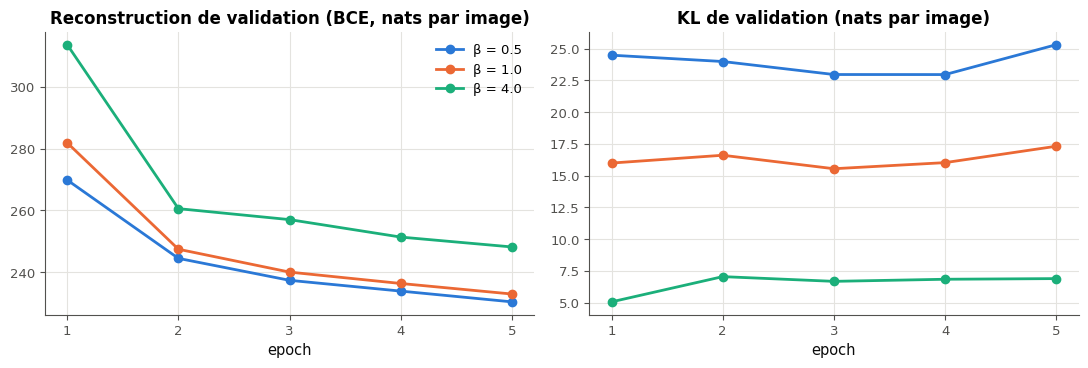

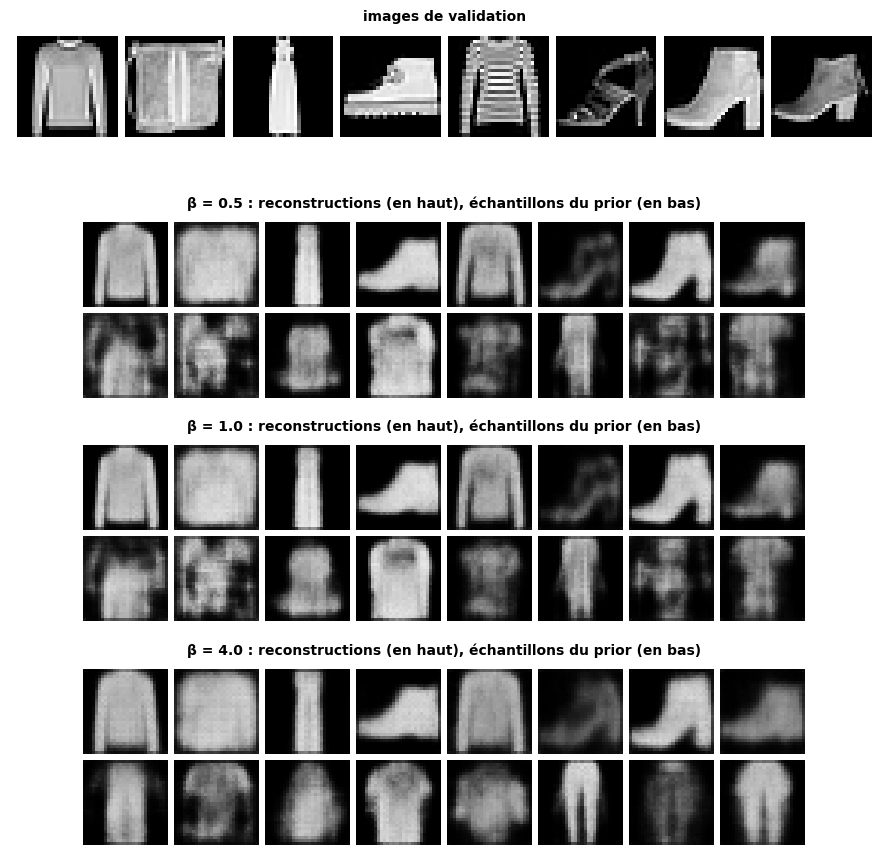

In [10]:
checks_of("MP6.3 comparaison")
VAE_RUNS = {}   # beta -> {"model", "history", "seconds", "fd", "active", "kl_per_latent"}
if ready("CLF_INFO", "REAL_FEATS", "BETA_RULE") and filled(BETA_RULE) and kit_ok():
    with attempt("MP6.3"):
        v, seed = CONFIG["vae"], CONFIG["seeds"][0]
        for beta in CONFIG["betas"]:
            genbench.set_seed(seed)
            model_v = genbench.ConvVAE(v["latent_dim"], v["width"]).to(DEVICE)
            history_v = genbench.train_vae(model_v, X_train_t[:v["n_train"]], epochs=v["epochs"], beta=beta, lr=v["lr"],
                                           batch_size=v["batch_size"], seed=seed, val_images=X_val_t[:CONFIG["n_eval"]])
            samples_v = genbench.sample_images(model_v, CONFIG["n_eval"], seed=SELECT_SEED)
            kl_v = genbench.kl_per_latent(model_v, X_val_t[:CONFIG["n_eval"]])
            VAE_RUNS[beta] = {"model": model_v, "history": history_v, "seconds": sum(history_v["seconds"]),
                              "fd": genbench.frechet_distance(REAL_FEATS, genbench.classifier_features(CLF, samples_v.to(DEVICE))),
                              "active": int((kl_v >= 0.01).sum()), "kl_per_latent": kl_v}
        print(f"VAE ({thousands(genbench.n_parameters(model_v))} paramètres, {v['latent_dim']} latents), "
              f"{thousands(v['n_train'])} images, {v['epochs']} epochs, graine {seed}\n")
        print("   β   reconstruction (val)   KL (val)   latents actifs   distance de Fréchet   secondes")
        for beta, run in VAE_RUNS.items():
            h = run["history"]
            print(f"{beta:5}   {h['val_rec'][-1]:20.1f}   {h['val_kl'][-1]:8.1f}   {run['active']:7d} / {v['latent_dim']:<5d}  "
                  f"{run['fd']:19.2f}   {run['seconds']:8.0f}")
        fig, (ax_r, ax_k) = plt.subplots(1, 2, figsize=(11, 3.8))
        for beta, run in VAE_RUNS.items():
            epochs_v = np.arange(1, len(run["history"]["val_rec"]) + 1)
            ax_r.plot(epochs_v, run["history"]["val_rec"], marker="o", label=f"β = {beta}")
            ax_k.plot(epochs_v, run["history"]["val_kl"], marker="o", label=f"β = {beta}")
        ax_r.set(title="Reconstruction de validation (BCE, nats par image)", xlabel="epoch")
        ax_k.set(title="KL de validation (nats par image)", xlabel="epoch")
        ax_r.legend()
        for ax in (ax_r, ax_k):
            ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        fig.tight_layout()
        save(fig, "vae_beta_courbes.png")
        plt.show()
        originals = X_val_t[:8]
        fig, axes = plt.subplots(len(VAE_RUNS) + 1, 1, figsize=(9, 1.4 + 2.5 * len(VAE_RUNS)))
        show_grid(axes[0], originals.cpu(), 8, "images de validation")
        for ax, (beta, run) in zip(axes[1:], VAE_RUNS.items()):
            with torch.no_grad():
                recon = torch.sigmoid(run["model"].eval()(originals)[0]).cpu()
            show_grid(ax, torch.cat([recon, genbench.sample_images(run["model"], 8, seed=SAMPLE_SEED)]), 8,
                      f"β = {beta} : reconstructions (en haut), échantillons du prior (en bas)")
        fig.tight_layout()
        save(fig, "vae_beta_echantillons.png")
        plt.show()
checks_done()

In [11]:
_eligible = [b for b, run in VAE_RUNS.items() if run["active"] >= CONFIG["vae"]["latent_dim"] // 2]
BETA = min(_eligible, key=lambda b: VAE_RUNS[b]["fd"]) if _eligible else ...
print("BETA =", BETA)

BETA = 0.5


In [12]:
checks_of("MP6.3 choix")
VAE_MODELS, VAE_HISTORIES = {}, {}
if VAE_RUNS and filled(BETA):
    if verdict("MP6.3", BETA in VAE_RUNS, f"β = {BETA} retenu (règle : {BETA_RULE}).",
               f"BETA doit être une des valeurs comparées, {list(VAE_RUNS)} (reçu {BETA!r})."):
        best = min(VAE_RUNS, key=lambda b: VAE_RUNS[b]["fd"])
        if BETA != best:
            print(f"ℹ️ MP6.3 : la plus petite distance de Fréchet est celle de β = {best} ; explique dans ton README "
                  "pourquoi ta règle en retient une autre.")
        VAE_MODELS[CONFIG["seeds"][0]] = VAE_RUNS[BETA]["model"]
        VAE_HISTORIES[CONFIG["seeds"][0]] = VAE_RUNS[BETA]["history"]
elif VAE_RUNS:
    pending("MP6.3", "BETA n'est pas encore choisi (la cellule précédente).")
checks_done()

✅ MP6.3 : β = 0.5 retenu (règle : la valeur de β dont les échantillons ont la plus petite distance de Fréchet (graine 0, graine de tirage SELECT_SEED), à condition que la moitié au moins des latents restent actifs).


✍️ **Observations (MP6.3)**

- **La règle** (écrite avant la comparaison) : la plus petite distance de Fréchet sur la graine 0, à condition de garder au moins la moitié des 16 latents actifs. En mode rapide (10 000 images, 5 epochs), elle retient β = 0,5 (200,6, contre 205,6 pour β = 1 et 261,2 pour β = 4) ; en mode complet (50 000 images, 15 epochs), β = 1 (214,9, contre 217,3 pour β = 0,5 et 277,6 pour β = 4). Les écarts entre 0,5 et 1 sont de l'ordre de l'écart entre graines (MP6.5) : la règle tranche, mais la mesure ne les sépare pas vraiment ; β = 4 est clairement moins bon.
- **L'effet de β** : la reconstruction de validation se dégrade quand β monte (mode complet : 213,5, 216,3 et 231,7 nats par image) pendant que la KL baisse (24,7, 17,2 et 7,4) : c'est le compromis du ch. 25. À β = 4, 7 latents sur 16 deviennent inactifs en mode complet (un effondrement partiel du posterior), et les échantillons sont plus flous et plus uniformes. Les échantillons des trois VAE sont flous, comme toujours avec une reconstruction par pixel indépendante.

## MP6.4 · DCGAN (option cGAN) : entraînement journalisé, checkpoints, reprise ⏱️ 150 min

**Objectif :** un GAN entraîné de façon stable, dont chaque epoch est journalisée, et qui reprend exactement là où il s'est arrêté.

a) Dans `genbench/models.py`, écris `generator_body` et `discriminator_body` (les règles de Radford, ch. 27, adaptées aux images 28 × 28 ; leurs docstrings donnent les couches dans l'ordre), les méthodes `forward` de `Generator` et de `Discriminator` (leurs `__init__` sont donnés ; avec `n_classes > 0`, le label entre par un embedding : c'est le GAN conditionnel) et `init_dcgan_weights`.
b) Dans `genbench/train.py`, écris `gan_step` (la loss **non saturante**, les faux détachés à l'étape du discriminateur), `save_checkpoint`, `load_checkpoint` et `train_gan` (leurs docstrings). Un seul `torch.Generator` tire l'ordre des images, le bruit et les labels des faux : avec lui, les deux réseaux, les deux optimiseurs et l'état aléatoire de PyTorch, le checkpoint suffit à reprendre **au bit près**.
c) La cellule d'entraînement entraîne le DCGAN de la graine 0, l'**interrompt** deux epochs avant la fin, puis le reprend depuis `runs/gan_seed0/last.pt` avec des réseaux neufs, comme après une coupure ; une grille d'échantillons pour un bruit fixé est tracée après chaque epoch, et `log.csv` garde une ligne par epoch. Avec `"conditional": True` dans `CONFIG["gan"]`, la cellule suivante entraîne aussi un GAN conditionnel (l'option du cahier des charges).

In [13]:
checks_of("MP6.4")
if kit_ok() and ready("X_train_t"):
    with attempt("MP6.4"):
        want_g = [nn.Linear, nn.BatchNorm1d, nn.ReLU, nn.Unflatten, nn.ConvTranspose2d, nn.BatchNorm2d, nn.ReLU,
                  nn.ConvTranspose2d, nn.Tanh]
        want_d = [nn.Conv2d, nn.LeakyReLU, nn.Conv2d, nn.BatchNorm2d, nn.LeakyReLU, nn.Flatten, nn.Linear]
        body_g, body_d = genbench.generator_body(64, 32), genbench.discriminator_body(1, 32)
        got_g, got_d = [type(m) for m in body_g], [type(m) for m in body_d]
        names = lambda types: ", ".join(t.__name__ for t in types)
        verdict("MP6.4", got_g == want_g and genbench.n_parameters(body_g) == 240_321 and body_g[0].bias is None
                and body_g[4].bias is None and body_g[7].bias is not None,
                "generator_body(64, 32) : les couches de Radford dans l'ordre, 240 321 paramètres, pas de biais avant une batchnorm.",
                f"generator_body(64, 32) : attendu {names(want_g)} (240 321 paramètres, sans biais devant une batchnorm), "
                f"reçu {names(got_g)} ({genbench.n_parameters(body_g)} paramètres).")
        slopes = [m.negative_slope for m in body_d if isinstance(m, nn.LeakyReLU)]
        verdict("MP6.4", got_d == want_d and genbench.n_parameters(body_d) == 36_577 and slopes == [0.2, 0.2]
                and body_d[2].bias is None,
                "discriminator_body(1, 32) : convolutions de pas 2, Leaky ReLU de pente 0,2, batchnorm sur la seconde "
                "seulement, des logits ; 36 577 paramètres.",
                f"discriminator_body(1, 32) : attendu {names(want_d)} (Leaky ReLU de pente 0,2 ; 36 577 paramètres), reçu "
                f"{names(got_d)} ({genbench.n_parameters(body_d)} paramètres).")
        torch.manual_seed(0)
        G_c, D_c = genbench.Generator(8, 4, n_classes=10).eval(), genbench.Discriminator(4, n_classes=10).eval()
        z_c, y_c = torch.randn(4, 8), torch.tensor([0, 3, 7, 9])
        with torch.no_grad():
            out_c = G_c(z_c, y_c)
            ok_g = torch.allclose(out_c, G_c.net(torch.cat([z_c, G_c.embed(y_c)], dim=1)))
            ok_d = torch.allclose(D_c(out_c, y_c), D_c.net(torch.cat([out_c, D_c.embed(y_c).view(-1, 1, 28, 28)], dim=1)))
        refusals = []
        for call in (lambda: G_c(z_c), lambda: genbench.Generator(8, 4)(z_c, y_c),
                     lambda: D_c(out_c), lambda: genbench.Discriminator(4)(out_c, y_c)):
            try:
                call()
                refusals.append(False)
            except ValueError:
                refusals.append(True)
        verdict("MP6.4", ok_g and ok_d and all(refusals),
                "Generator et Discriminator conditionnels : l'embedding du label après z, ou en second canal après l'image ; "
                "des labels manquants ou en trop lèvent ValueError.",
                "Generator.forward doit concaténer embed(labels) APRÈS z, puis appliquer net ; Discriminator.forward, "
                "ajouter embed(labels) mis en forme (N, 1, 28, 28) comme second canal APRÈS l'image ; ValueError quand un "
                f"réseau conditionnel ne reçoit pas de labels, ou un réseau simple en reçoit (refus : {refusals}).")
        torch.manual_seed(0)
        G_i = genbench.Generator(64, 32, n_classes=10)
        embed_before = G_i.embed.weight.detach().clone()
        G_i.apply(genbench.init_dcgan_weights)
        stds = [m.weight.std().item() for m in G_i.modules() if isinstance(m, (nn.Linear, nn.ConvTranspose2d))]
        bns = [m for m in G_i.modules() if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d))]
        verdict("MP6.4", all(abs(s - 0.02) < 0.004 for s in stds)
                and all(abs(m.weight.mean().item() - 1) < 0.01 and m.bias.abs().max().item() == 0 for m in bns)
                and torch.equal(embed_before, G_i.embed.weight),
                "init_dcgan_weights : poids ~ N(0 ; 0,02²), batchnorms ~ N(1 ; 0,02²) et biais nuls, embedding intact.",
                f"init_dcgan_weights : écarts-types des poids {np.round(stds, 4).tolist()}, attendu 0,02 ; les batchnorms "
                "doivent avoir des poids près de 1 et des biais nuls, et l'embedding ne doit pas changer.")

        def tiny_gan(conditional=False, seed=0):
            torch.manual_seed(seed)
            G_t = genbench.Generator(8, 4, n_classes=10 if conditional else 0)
            D_t = genbench.Discriminator(4, n_classes=10 if conditional else 0)
            G_t.apply(genbench.init_dcgan_weights)
            D_t.apply(genbench.init_dcgan_weights)
            return G_t, D_t

        adam = lambda model: torch.optim.Adam(model.parameters(), lr=1e-2, betas=(0.5, 0.999))
        x_g, y_g = X_train_t[:64].cpu(), y_train_t[:64].cpu()
        real_g, z_g, fl_g = x_g[:16] * 2 - 1, torch.randn(16, 8), torch.randint(0, 10, (16,))
        G_1, D_1 = tiny_gan(conditional=True)
        G_2, D_2 = copy.deepcopy(G_1), copy.deepcopy(D_1)
        calls = [0]
        hook = G_1.net[0].weight.register_hook(lambda grad: calls.__setitem__(0, calls[0] + 1))
        try:
            out_s = genbench.gan_step(G_1, D_1, adam(G_1), adam(D_1), real_g, z_g, y_g[:16], fl_g)
        except RuntimeError as exc:
            if "second time" not in str(exc):
                raise
            verdict("MP6.4", False, "", "gan_step : PyTorch refuse de remonter deux fois le même graphe (« backward through "
                    "the graph a second time ») : à l'étape de D, juge fake.detach() ; sinon loss_d.backward() remonte "
                    "jusqu'à G et libère son graphe, dont l'étape de G a encore besoin. Les vérifications suivantes de "
                    "MP6.4 attendent cette correction.")
            raise StopCheck
        finally:
            hook.remove()
        opt_g2, opt_d2 = adam(G_2), adam(D_2)
        fake = G_2(z_g, fl_g)
        a, b = D_2(real_g, y_g[:16]), D_2(fake.detach(), fl_g)
        loss_d = F.binary_cross_entropy_with_logits(a, torch.ones_like(a)) + F.binary_cross_entropy_with_logits(b, torch.zeros_like(b))
        opt_d2.zero_grad()
        loss_d.backward()
        opt_d2.step()
        c = D_2(fake, fl_g)
        loss_g = F.binary_cross_entropy_with_logits(c, torch.ones_like(c))
        opt_g2.zero_grad()
        loss_g.backward()
        opt_g2.step()
        gap_s = max(weight_gap(G_1, G_2), weight_gap(D_1, D_2))
        same_step = abs(out_s["loss_d"] - loss_d.item()) < 1e-4 and abs(out_s["loss_g"] - loss_g.item()) < 1e-4
        rounding = (" ; les losses concordent : l'écart des poids vient sans doute d'arrondis (une formule équivalente ?), "
                    "mais au-delà de 1e-4 c'est autre chose" if same_step else "")
        verdict("MP6.4", gap_s < 1e-4 and same_step and abs(out_s["d_real"] - torch.sigmoid(a).mean().item()) < 1e-5,
                "gan_step : les poids et les losses d'un pas écrit à la main (D puis G, loss non saturante, D à jour pour G).",
                f"gan_step : écart de {gap_s:.1e} aux poids d'un pas écrit à la main{rounding} ; attendu loss_d = "
                f"{loss_d.item():.6f} et loss_g = {loss_g.item():.6f}, reçu {out_s['loss_d']:.6f} et {out_s['loss_g']:.6f} : D apprend vrais → 1 "
                "et faux détachés → 0, puis G veut que le D MIS À JOUR juge ses faux vrais (label 1), et seul opt_g fait un pas.")
        verdict("MP6.4", calls[0] == 1, "gan_step : les faux sont détachés à l'étape de D (un seul passage du gradient dans G).",
                f"gan_step : le gradient a traversé G {calls[0]} fois au lieu d'une : à l'étape de D, juge fake.detach(), "
                "sinon loss_d.backward() remonte jusqu'aux poids de G.")
        folder_k = Path(tempfile.mkdtemp())
        gen_k = torch.Generator().manual_seed(9)
        opt_gk, opt_dk = adam(G_1), adam(D_1)
        genbench.gan_step(G_1, D_1, opt_gk, opt_dk, real_g, z_g, y_g[:16], fl_g)
        genbench.save_checkpoint(folder_k / "last.pt", G_1, D_1, opt_gk, opt_dk, 3, {"loss_d": [1.5]}, gen_k)
        draw_k = torch.rand(3)
        try:
            torch.load(folder_k / "last.pt", weights_only=True)
            safe_k = True
        except Exception:
            safe_k = False
        G_3, D_3 = tiny_gan(conditional=True, seed=1)
        opt_g3, opt_d3, gen_3 = adam(G_3), adam(D_3), torch.Generator().manual_seed(1)
        torch.manual_seed(999)
        epoch_k, history_k = genbench.load_checkpoint(folder_k / "last.pt", G_3, D_3, opt_g3, opt_d3, gen_3)
        restored = (weight_gap(G_1, G_3) == 0 and weight_gap(D_1, D_3) == 0 and torch.equal(gen_k.get_state(), gen_3.get_state())
                    and torch.equal(torch.rand(3), draw_k)
                    and torch.equal(opt_g3.state_dict()["state"][0]["exp_avg"], opt_gk.state_dict()["state"][0]["exp_avg"]))
        verdict("MP6.4", safe_k and restored and epoch_k == 3 and history_k == {"loss_d": [1.5]},
                "save_checkpoint et load_checkpoint : G, D, les deux optimiseurs, l'epoch, l'historique, le générateur et "
                "l'état aléatoire global ; le fichier se recharge avec weights_only=True.",
                "après load_checkpoint, il manque quelque chose : les poids de G et D, les moments d'Adam des deux "
                "optimiseurs, l'état du torch.Generator, l'état global (torch.get_rng_state), l'epoch et l'historique "
                f"(rendus : {epoch_k}, {history_k}) ; le fichier doit se recharger avec weights_only=True "
                f"({'oui' if safe_k else 'non'} : n'y mets que des tenseurs, des nombres, des listes et des dicts).")
        G_h, D_h = tiny_gan(conditional=True)
        G_a, D_a = copy.deepcopy(G_h), copy.deepcopy(D_h)
        epochs_seen = []
        history_t = genbench.train_gan(G_a, D_a, x_g, labels=y_g, epochs=1, lr=1e-2, batch_size=20, seed=4,
                                       on_epoch=lambda epoch, G: epochs_seen.append(epoch))
        opt_gh, opt_dh, gen_h = adam(G_h), adam(D_h), torch.Generator().manual_seed(4)
        G_h.train()
        D_h.train()
        order = torch.randperm(64, generator=gen_h)
        losses_h = []
        for i in range(0, 64 - 20 + 1, 20):                       # 3 mini-batches of 20: the last 4 images are dropped
            idx = order[i:i + 20]
            z_h = torch.randn(20, 8, generator=gen_h)
            fl_h = torch.randint(0, 10, (20,), generator=gen_h)
            losses_h.append(genbench.gan_step(G_h, D_h, opt_gh, opt_dh, x_g[idx] * 2 - 1, z_h, y_g[idx], fl_h)["loss_d"])
        gap_t = weight_gap(G_a, G_h)
        verdict("MP6.4", gap_t < 1e-5 and len(history_t["steps"]["loss_d"]) == 3
                and np.allclose(history_t["steps"]["loss_d"], losses_h, atol=1e-5) and epochs_seen == [1]
                and abs(history_t["loss_d"][0] - np.mean(losses_h)) < 1e-5 and not G_a.training,
                "train_gan : une epoch identique à une boucle écrite à la main (Adam β₁ = 0,5, l'ordre, puis le bruit et "
                "les labels des faux tirés par un seul générateur, le dernier mini-batch incomplet laissé) ; on_epoch appelé.",
                f"train_gan : écart de {gap_t:.1e} à la boucle écrite à la main, {len(history_t['steps']['loss_d'])} pas au "
                "lieu de 3 : Adam(lr, betas=(0.5, 0.999)) pour chaque réseau, images ramenées dans [-1, 1], "
                "torch.randperm(n, generator=generator), puis pour chaque mini-batch complet torch.randn(m, latent_dim, "
                "generator=generator) et torch.randint(0, n_classes, (m,), generator=generator), dans cet ordre ; "
                "on_epoch(epoch, G) après chaque epoch ; G et D en mode évaluation à la fin.")

        def resumable(folder, stop=None, resume=False):
            G_r, D_r = tiny_gan(conditional=True)
            history_r = genbench.train_gan(G_r, D_r, x_g, labels=y_g, epochs=3, batch_size=16, seed=2, folder=folder,
                                           stop_after=stop, resume=resume)
            return G_r, history_r

        straight, history_s = resumable(Path(tempfile.mkdtemp()))
        folder_r = Path(tempfile.mkdtemp())
        resumable(folder_r, stop=1)                                # an older run in the same folder: its journal goes
        resumable(folder_r, stop=2)
        resumed, history_r = resumable(folder_r, resume=True)
        gap_r = weight_gap(straight, resumed)
        rows = (folder_r / "log.csv").read_text(encoding="utf-8").splitlines() if (folder_r / "log.csv").exists() else []
        verdict("MP6.4", gap_r == 0.0 and history_r["loss_g"] == history_s["loss_g"],
                "reprise exacte : 2 epochs, une interruption, puis 1 epoch = 3 epochs d'affilée, au bit près (poids et historique).",
                (f"après la reprise, les poids diffèrent de ceux de 3 epochs d'affilée (écart {gap_r:.2e})" if gap_r else
                 "après la reprise, l'historique diffère de celui de 3 epochs d'affilée")
                + " : last.pt doit garder les deux réseaux, les deux optimiseurs, l'epoch, l'historique, l'état du "
                "générateur et l'état global de PyTorch, et train_gan(resume=True) tout restaurer avant l'epoch suivante.")
        verdict("MP6.4", bool(rows) and rows[0].split(",") == genbench.LOG_COLUMNS and len(rows) == 4,
                "log.csv : un en-tête et une ligne par epoch (2 avant l'interruption, 1 après) ; le journal d'un run plus "
                "ancien du même dossier est remplacé.",
                f"log.csv doit avoir l'en-tête LOG_COLUMNS et une ligne par epoch : un nouveau run (sans resume) "
                f"recommence le journal, une reprise l'allonge (attendu 4 lignes, reçu {len(rows)}).")
        try:
            resumable(Path(tempfile.mkdtemp()), resume=True)
            refused_r = False
        except FileNotFoundError:
            refused_r = True
        verdict("MP6.4", refused_r, "train_gan(resume=True) sans last.pt lève FileNotFoundError.",
                "train_gan(resume=True) dans un dossier sans last.pt doit lever FileNotFoundError, pas repartir de zéro "
                "en silence.")
checks_done()

✅ MP6.4 : generator_body(64, 32) : les couches de Radford dans l'ordre, 240 321 paramètres, pas de biais avant une batchnorm.
✅ MP6.4 : discriminator_body(1, 32) : convolutions de pas 2, Leaky ReLU de pente 0,2, batchnorm sur la seconde seulement, des logits ; 36 577 paramètres.
✅ MP6.4 : Generator et Discriminator conditionnels : l'embedding du label après z, ou en second canal après l'image ; des labels manquants ou en trop lèvent ValueError.
✅ MP6.4 : init_dcgan_weights : poids ~ N(0 ; 0,02²), batchnorms ~ N(1 ; 0,02²) et biais nuls, embedding intact.
✅ MP6.4 : gan_step : les poids et les losses d'un pas écrit à la main (D puis G, loss non saturante, D à jour pour G).
✅ MP6.4 : gan_step : les faux sont détachés à l'étape de D (un seul passage du gradient dans G).
✅ MP6.4 : save_checkpoint et load_checkpoint : G, D, les deux optimiseurs, l'epoch, l'historique, le générateur et l'état aléatoire global ; le fichier se recharge avec weights_only=True.
✅ MP6.4 : train_gan : une epoch ide

✅ MP6.4 : reprise exacte : 2 epochs, une interruption, puis 1 epoch = 3 epochs d'affilée, au bit près (poids et historique).
✅ MP6.4 : log.csv : un en-tête et une ligne par epoch (2 avant l'interruption, 1 après) ; le journal d'un run plus ancien du même dossier est remplacé.
✅ MP6.4 : train_gan(resume=True) sans last.pt lève FileNotFoundError.


DCGAN : G 240 321 paramètres, D 36 577 ; 10 000 images, 5 epochs, graine 0


⏸️ interruption simulée après l'epoch 3 ; reprise depuis runs/gan_seed0_rapide/last.pt avec des réseaux neufs


epoch,loss_d,loss_g,d_real,d_fake,seconds
1,0.20512,3.13968,0.90733,0.07987,4.69453
2,0.56229,1.97743,0.77954,0.21181,5.16043
3,0.65926,1.59161,0.74147,0.25531,4.70069
4,0.62662,1.66125,0.7532,0.24156,5.03428
5,0.83999,1.43745,0.69092,0.30554,4.95084

✅ MP6.4 : 5 epochs journalisées (3 avant l'interruption), une grille par epoch, en 25 s.


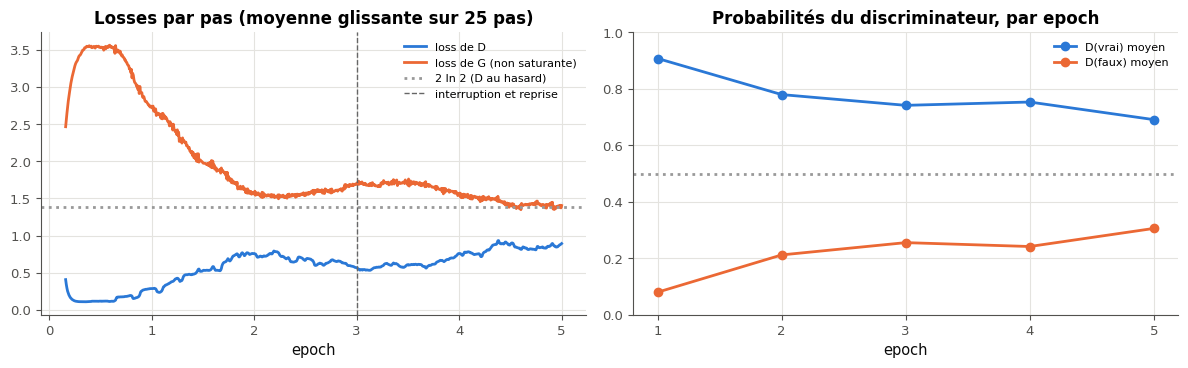

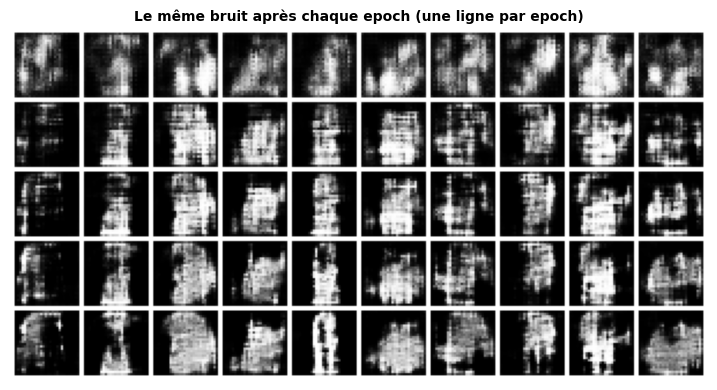

In [14]:
checks_of("MP6.4 entraînement")
GAN_MODELS, GAN_HISTORIES, GAN_SNAPSHOTS = {}, {}, []
if ready("CONFIG_SAVED", "X_train_t") and kit_ok():
    with attempt("MP6.4"):
        g, seed = CONFIG["gan"], CONFIG["seeds"][0]
        folder_g = RUNS_DIR / f"gan_seed{seed}{SUFFIX}"
        shutil.rmtree(folder_g, ignore_errors=True)
        fixed_z = torch.randn(10, g["latent_dim"], generator=torch.Generator().manual_seed(SAMPLE_SEED))

        def new_gan(seed, conditional=False):
            """A new DCGAN (Radford's initialization), built after set_seed(seed)."""
            genbench.set_seed(seed)
            n_classes = 10 if conditional else 0
            G_n = genbench.Generator(g["latent_dim"], g["width"], n_classes).to(DEVICE)
            D_n = genbench.Discriminator(g["width"], n_classes).to(DEVICE)
            G_n.apply(genbench.init_dcgan_weights)
            D_n.apply(genbench.init_dcgan_weights)
            return G_n, D_n

        snapshot = lambda epoch, G: GAN_SNAPSHOTS.append(genbench.decode_codes(G, fixed_z))
        settings = dict(epochs=g["epochs"], lr=g["lr"], batch_size=g["batch_size"], seed=seed, folder=folder_g,
                        on_epoch=snapshot)
        stop = max(1, g["epochs"] - 2)
        G_0, D_0 = new_gan(seed)
        print(f"DCGAN : G {thousands(genbench.n_parameters(G_0))} paramètres, D {thousands(genbench.n_parameters(D_0))} ; "
              f"{thousands(g['n_train'])} images, {g['epochs']} epochs, graine {seed}")
        genbench.train_gan(G_0, D_0, X_train_t[:g["n_train"]], stop_after=stop, **settings)
        print(f"⏸️ interruption simulée après l'epoch {stop} ; reprise depuis runs/{folder_g.name}/last.pt avec des réseaux neufs")
        G_0, D_0 = new_gan(seed + 1000)                              # brand-new objects, as after a crash
        gan_history = genbench.train_gan(G_0, D_0, X_train_t[:g["n_train"]], resume=True, **settings)
        print((folder_g / "log.csv").read_text(encoding="utf-8"))
        verdict("MP6.4", len(gan_history["loss_d"]) == g["epochs"] and len(GAN_SNAPSHOTS) == g["epochs"],
                f"{g['epochs']} epochs journalisées ({stop} avant l'interruption), une grille par epoch, en "
                f"{sum(gan_history['seconds']):.0f} s.",
                f"l'historique a {len(gan_history['loss_d'])} epochs au lieu de {g['epochs']} après la reprise.")
        GAN_MODELS[seed], GAN_HISTORIES[seed] = G_0, gan_history
        steps = np.arange(1, len(gan_history["steps"]["loss_d"]) + 1) / (len(gan_history["steps"]["loss_d"]) / g["epochs"])
        smooth = lambda series: np.convolve(series, np.ones(25) / 25, mode="valid")
        fig, (ax_l, ax_p) = plt.subplots(1, 2, figsize=(12, 3.8))
        ax_l.plot(steps[24:], smooth(gan_history["steps"]["loss_d"]), label="loss de D")
        ax_l.plot(steps[24:], smooth(gan_history["steps"]["loss_g"]), label="loss de G (non saturante)")
        ax_l.axhline(2 * np.log(2), color="0.6", ls=":", label="2 ln 2 (D au hasard)")
        ax_l.axvline(stop, color="0.4", ls="--", lw=1, label="interruption et reprise")
        ax_l.set(title="Losses par pas (moyenne glissante sur 25 pas)", xlabel="epoch")
        ax_l.legend(fontsize=8)
        epochs_g = np.arange(1, g["epochs"] + 1)
        ax_p.plot(epochs_g, gan_history["d_real"], marker="o", label="D(vrai) moyen")
        ax_p.plot(epochs_g, gan_history["d_fake"], marker="o", label="D(faux) moyen")
        ax_p.axhline(0.5, color="0.6", ls=":")
        ax_p.set(title="Probabilités du discriminateur, par epoch", xlabel="epoch", ylim=(0, 1))
        ax_p.legend(fontsize=8)
        ax_p.xaxis.set_major_locator(MaxNLocator(integer=True))
        fig.tight_layout()
        save(fig, "gan_courbes.png")
        plt.show()
        fig, ax = plt.subplots(figsize=(9, 1.0 + 0.95 * len(GAN_SNAPSHOTS)))
        show_grid(ax, torch.cat(GAN_SNAPSHOTS), 10, "Le même bruit après chaque epoch (une ligne par epoch)")
        save(fig, "gan_progression.png")
        plt.show()
checks_done()

In [15]:
CGAN = None
if ready("GAN_MODELS") and GAN_MODELS and CONFIG["gan"].get("conditional") and kit_ok():
    with attempt("MP6.4"):
        G_c, D_c = new_gan(CONFIG["seeds"][0], conditional=True)
        cgan_history = genbench.train_gan(G_c, D_c, X_train_t[:g["n_train"]], labels=y_train_t[:g["n_train"]],
                                          epochs=g["epochs"], lr=g["lr"], batch_size=g["batch_size"], seed=CONFIG["seeds"][0])
        CGAN = G_c
        print(f"GAN conditionnel (graine {CONFIG['seeds'][0]}) : {g['epochs']} epochs en {sum(cgan_history['seconds']):.0f} s ; "
              f"loss de D finale {cgan_history['loss_d'][-1]:.3f}, D(faux) {cgan_history['d_fake'][-1]:.3f}")
elif ready("GAN_MODELS") and GAN_MODELS:
    print("ℹ️ MP6.4 : pas de GAN conditionnel (CONFIG['gan']['conditional'] est faux) : l'option est facultative.")
elif ready("GAN_MODELS"):
    print("⏳ MP6.4 : le GAN conditionnel attend l'entraînement du DCGAN (la cellule précédente).")

GAN conditionnel (graine 0) : 5 epochs en 30 s ; loss de D finale 0.941, D(faux) 0.349


✍️ **Observations (MP6.4)**

- **Les courbes** : en mode complet, après une première epoch où D gagne nettement (D(vrai) 0,75, D(faux) 0,25), les deux losses se stabilisent dès la quatrième epoch (D vers 1,15, G vers 1,05) avec D(vrai) ≈ 0,59 et D(faux) ≈ 0,41 : un équilibre stable, pas l'équilibre théorique (0,5 et 2 ln 2), car D garde une petite avance. Aucune explosion, aucune loss de D qui tombe à 0 : l'entraînement est stable, et la grille du bruit fixe s'affine d'epoch en epoch. En mode rapide, 5 epochs sur 10 000 images, D garde plus d'avance (D(faux) 0,31 à la fin) et les images restent bruitées.
- **Le checkpoint** : `last.pt` garde les deux réseaux (avec les statistiques de leurs batchnorms), les deux optimiseurs (les moments d'Adam), l'epoch, l'historique, l'état du `torch.Generator` qui tire l'ordre, le bruit et les labels des faux, et l'état global de PyTorch. Sans les moments d'Adam, le premier pas après la reprise serait celui d'un Adam neuf ; sans le générateur, les mini-batches et le bruit changeraient : la reprise donnerait un autre GAN. La courbe ne montre aucune marche à l'interruption (epoch 3 en mode rapide, 8 en mode complet).

## MP6.5 · Évaluation : distance de Fréchet sur 3 graines, classes générées, plus proches voisins ⏱️ 90 min

**Objectif :** appliquer le protocole de MP6.1, tel qu'il a été écrit, aux deux générateurs, sur trois graines.

a) Dans `genbench/evaluate.py`, écris `class_report` (ce que le classifieur voit dans un ensemble d'images : la répartition des classes, son entropie normalisée, la plus grande part et la confiance moyenne) et `nearest_neighbors` (pour chaque image, la plus proche image de référence en distance euclidienne entre pixels, par blocs).
b) Les deux cellules suivantes entraînent le VAE (β retenu) et le DCGAN avec les deux autres graines de `CONFIG["seeds"]`, sans rien changer d'autre. La cellule d'évaluation tire `n_eval` images de chaque générateur et de chaque graine, avec une graine de tirage différente de celle du choix de β, puis mesure : la distance de Fréchet aux images de validation, à côté du plancher de MP6.2 ; la répartition des classes prédites (un effondrement de mode se voit à une classe absente ou envahissante) ; la mémorisation, en comparant la distance de chaque échantillon à son plus proche voisin d'entraînement à la même distance pour de vraies images de validation. Elle écrit `results_rapide.json` (mode rapide) ou `results.json` (mode complet). En mode complet, la cellule des deux DCGAN dure environ un quart d'heure sur un CPU à deux cœurs (🚀). En mode rapide, chaque mesure porte sur 2 000 images et les modèles sont petits : les chiffres sont plus bruités qu'en mode complet, mais le protocole est le même.

In [16]:
checks_of("MP6.5")
if kit_ok() and ready("X_train_t"):
    with attempt("MP6.5"):
        class FixedLogits(nn.Module):
            """A fake classifier that returns given logits, whatever the images (and has one parameter)."""

            def __init__(self, logits):
                super().__init__()
                self.logits, self.dummy = logits, nn.Parameter(torch.zeros(1))

            def forward(self, x):
                return self.logits[: len(x)]

        uniform = genbench.class_report(FixedLogits(torch.eye(10).repeat(3, 1) * 5), torch.zeros(30, 1, 28, 28))
        mixed_logits = torch.eye(10)[[4] * 6 + [1] * 2] * 5
        mixed = genbench.class_report(FixedLogits(mixed_logits), torch.zeros(8, 1, 28, 28))
        p_m = np.array([0.75, 0.25])
        want_entropy = float(-(p_m * np.log(p_m)).sum() / np.log(10))
        want_conf = torch.softmax(mixed_logits, dim=1).max(1).values.mean().item()
        verdict("MP6.5", uniform["counts"] == [3] * 10 and abs(uniform["entropy"] - 1) < 1e-9
                and mixed["counts"] == [0, 2, 0, 0, 6, 0, 0, 0, 0, 0] and abs(mixed["entropy"] - want_entropy) < 1e-9
                and abs(mixed["max_share"] - 0.75) < 1e-12 and abs(mixed["confidence"] - want_conf) < 1e-6,
                f"class_report : 3 images par classe → entropie 1 ; 6 et 2 images dans deux classes → entropie "
                f"{want_entropy:.4f}, plus grande part 0,75.",
                f"class_report : attendu counts [0, 2, 0, 0, 6, 0, 0, 0, 0, 0], une entropie de {want_entropy:.4f} (en nats, "
                f"divisée par ln 10 ; les classes vides ne comptent pas), max_share 0,75 et une confiance de {want_conf:.4f} "
                f"(la probabilité moyenne de la classe prédite) ; reçu {mixed}.")
        queries, references = X_val_t[:7].cpu(), X_train_t[:50].cpu()
        references = torch.cat([references, references[:5]])        # duplicates: the first index wins
        dist_n, idx_n = genbench.nearest_neighbors(queries, references, batch_size=3)
        q_n, r_n = queries.reshape(7, -1).double().numpy(), references.reshape(55, -1).double().numpy()
        full_n = np.sqrt(((q_n[:, None, :] - r_n[None, :, :]) ** 2).sum(-1))
        verdict("MP6.5", isinstance(idx_n, np.ndarray) and np.array_equal(idx_n, full_n.argmin(1))
                and np.allclose(dist_n, full_n.min(1), atol=1e-4),
                "nearest_neighbors : les indices et les distances euclidiennes (pas au carré) d'un calcul NumPy complet, par blocs de 3.",
                f"nearest_neighbors : attendu les indices {full_n.argmin(1).tolist()} et les distances "
                f"{np.round(full_n.min(1), 3).tolist()} (la racine de la somme des carrés des écarts de pixels), reçu "
                f"{np.asarray(idx_n).tolist()} et {np.round(dist_n, 3).tolist()}.")
checks_done()

✅ MP6.5 : class_report : 3 images par classe → entropie 1 ; 6 et 2 images dans deux classes → entropie 0.2442, plus grande part 0,75.
✅ MP6.5 : nearest_neighbors : les indices et les distances euclidiennes (pas au carré) d'un calcul NumPy complet, par blocs de 3.


In [17]:
checks_of("MP6.5 VAE")
if ready("VAE_MODELS", "BETA") and VAE_MODELS and kit_ok():
    with attempt("MP6.5"):
        v = CONFIG["vae"]
        for seed in CONFIG["seeds"][1:]:
            genbench.set_seed(seed)
            model_v = genbench.ConvVAE(v["latent_dim"], v["width"]).to(DEVICE)
            VAE_HISTORIES[seed] = genbench.train_vae(model_v, X_train_t[:v["n_train"]], epochs=v["epochs"], beta=BETA,
                                                     lr=v["lr"], batch_size=v["batch_size"], seed=seed,
                                                     val_images=X_val_t[:CONFIG["n_eval"]])
            VAE_MODELS[seed] = model_v
            print(f"VAE β = {BETA}, graine {seed} : reconstruction de validation {VAE_HISTORIES[seed]['val_rec'][-1]:.1f}, "
                  f"KL {VAE_HISTORIES[seed]['val_kl'][-1]:.1f} ({sum(VAE_HISTORIES[seed]['seconds']):.0f} s)")
checks_done()

VAE β = 0.5, graine 1 : reconstruction de validation 230.5, KL 25.3 (11 s)


VAE β = 0.5, graine 2 : reconstruction de validation 233.1, KL 24.6 (12 s)


In [18]:
checks_of("MP6.5 GAN")
if ready("GAN_MODELS", "new_gan") and GAN_MODELS and kit_ok():
    with attempt("MP6.5"):
        g = CONFIG["gan"]
        for seed in CONFIG["seeds"][1:]:
            G_s, D_s = new_gan(seed)
            GAN_HISTORIES[seed] = genbench.train_gan(G_s, D_s, X_train_t[:g["n_train"]], epochs=g["epochs"], lr=g["lr"],
                                                     batch_size=g["batch_size"], seed=seed)
            GAN_MODELS[seed] = G_s
            print(f"DCGAN graine {seed} : loss de D finale {GAN_HISTORIES[seed]['loss_d'][-1]:.3f}, D(faux) "
                  f"{GAN_HISTORIES[seed]['d_fake'][-1]:.3f} ({sum(GAN_HISTORIES[seed]['seconds']):.0f} s)")
checks_done()

DCGAN graine 1 : loss de D finale 0.863, D(faux) 0.316 (25 s)


DCGAN graine 2 : loss de D finale 0.822, D(faux) 0.304 (24 s)


distance de Fréchet à 2 000 images de validation (plancher, deux échantillons réels : 1.27)

modèle  graine   distance   entropie des classes   plus grande part   confiance
VAE          0     203.03                0.920              0.194       0.576
VAE          1     206.46                0.923              0.223       0.573
VAE          2     252.34                0.824              0.253       0.572
DCGAN        0     128.70                0.932              0.226       0.598
DCGAN        1     128.61                0.901              0.251       0.611
DCGAN        2     123.63                0.928              0.216       0.592
cGAN         0      51.39                0.983              0.141       0.803
réel         —       1.27                0.994              0.118       0.889
VAE : distance moyenne 220.61 ± 27.53 (écart-type sur 3 graines)
DCGAN : distance moyenne 126.98 ± 2.90 (écart-type sur 3 graines)
cGAN : distance moyenne 51.39
cGAN : le classifieur retrouve la classe d


mémorisation (2 000 images, distance euclidienne au plus proche voisin parmi 10 000 images d'entraînement) :
  validation (réelles) : médiane 3.86, seuil des copies (quantile 0.01) 1.87
  VAE   : médiane 4.76, minimum 1.80, copies 0.1% (attendu par hasard : 1%)
  DCGAN : médiane 6.37, minimum 2.27, copies 0.0% (attendu par hasard : 1%)


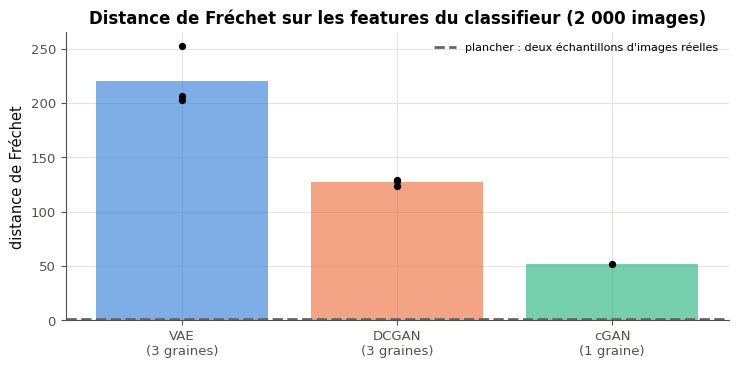

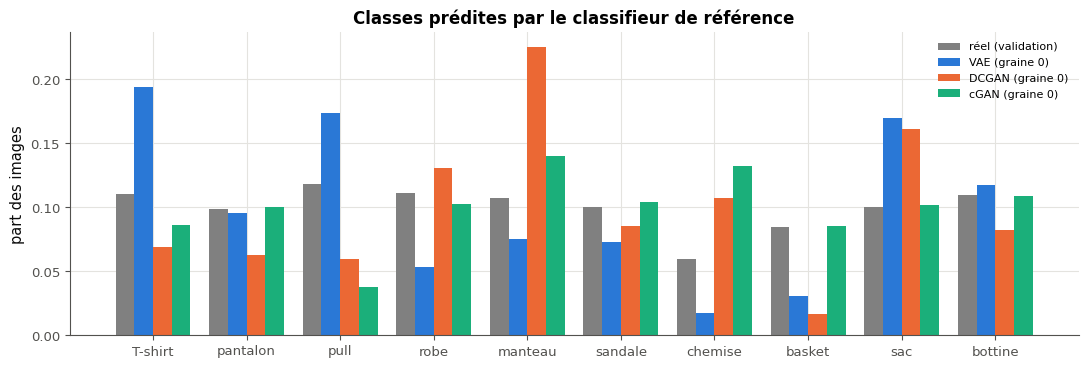

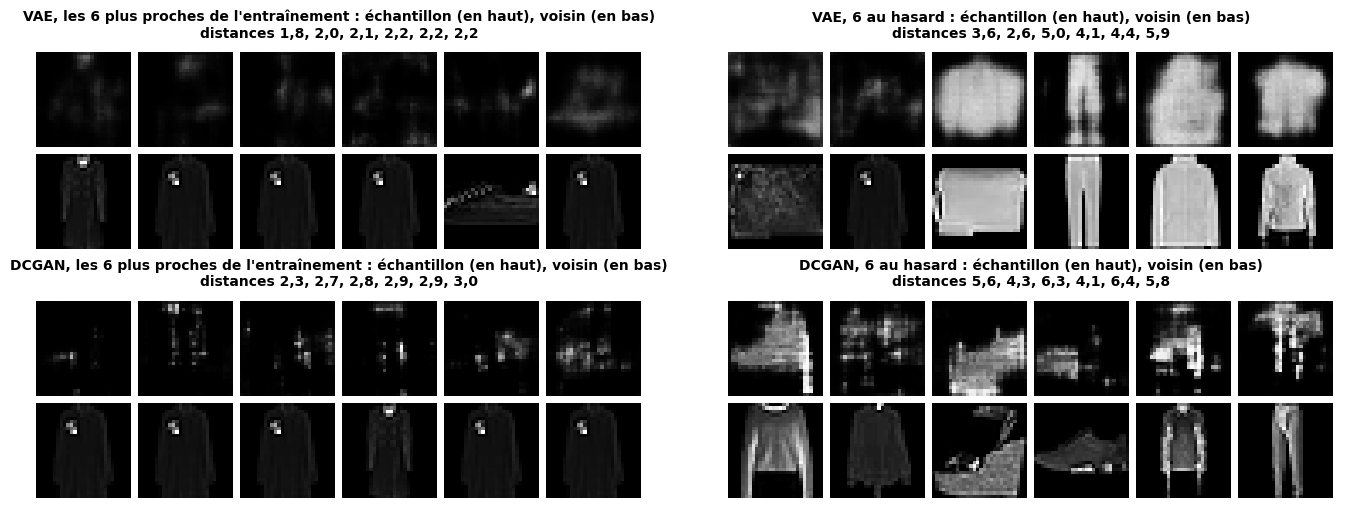

💾 results_rapide.json écrit.


In [19]:
checks_of("MP6.5 évaluation")
EVALUATION = {}
if ready("VAE_MODELS", "GAN_MODELS", "REAL_FEATS") and len(VAE_MODELS) == 3 and len(GAN_MODELS) == 3 and kit_ok():
    with attempt("MP6.5"):
        n_eval, seeds = CONFIG["n_eval"], CONFIG["seeds"]
        floor = CLF_INFO["references"]["plancher : d'autres images réelles"]
        real_report = genbench.class_report(CLF, X_val_t[:n_eval])
        SAMPLES = {}
        for name, models in (("VAE", VAE_MODELS), ("DCGAN", GAN_MODELS)):
            EVALUATION[name] = {}
            for seed, model in models.items():
                samples = genbench.sample_images(model, n_eval, seed=1000 + seed)       # not SELECT_SEED
                SAMPLES[(name, seed)] = samples
                report = genbench.class_report(CLF, samples.to(DEVICE))
                EVALUATION[name][seed] = {"fd": genbench.frechet_distance(REAL_FEATS, genbench.classifier_features(CLF, samples.to(DEVICE))),
                                          **report}
        if CGAN is not None:
            wanted = torch.arange(10).repeat_interleave(n_eval // 10)
            samples_c = genbench.sample_images(CGAN, len(wanted), seed=1000 + seeds[0], labels=wanted)
            report_c = genbench.class_report(CLF, samples_c.to(DEVICE))
            agreement = float((genbench.predict_proba(CLF, samples_c.to(DEVICE)).argmax(1) == wanted.numpy()).mean())
            EVALUATION["cGAN"] = {seeds[0]: {"fd": genbench.frechet_distance(REAL_FEATS, genbench.classifier_features(CLF, samples_c.to(DEVICE))),
                                             **report_c, "conditional_accuracy": agreement}}
        print(f"distance de Fréchet à {thousands(n_eval)} images de validation (plancher, deux échantillons réels : {floor:.2f})\n")
        print("modèle  graine   distance   entropie des classes   plus grande part   confiance")
        for name, per_seed in EVALUATION.items():
            for seed, r in per_seed.items():
                print(f"{name:7} {seed:6d} {r['fd']:10.2f} {r['entropy']:20.3f} {r['max_share']:18.3f} {r['confidence']:11.3f}")
        print(f"réel    {'—':>6} {floor:10.2f} {real_report['entropy']:20.3f} {real_report['max_share']:18.3f} {real_report['confidence']:11.3f}")
        SUMMARY = {name: {"fd_mean": float(np.mean([r["fd"] for r in per_seed.values()])),
                          "fd_std": float(np.std([r["fd"] for r in per_seed.values()], ddof=1)) if len(per_seed) > 1 else None}
                   for name, per_seed in EVALUATION.items()}
        for name, s in SUMMARY.items():
            print(f"{name} : distance moyenne {s['fd_mean']:.2f}" + (f" ± {s['fd_std']:.2f} (écart-type sur 3 graines)" if s["fd_std"] else ""))
        if CGAN is not None:
            print(f"cGAN : le classifieur retrouve la classe demandée pour {agreement:.1%} des échantillons")
        verdict("MP6.5", all(len(EVALUATION[name]) == 3 for name in ("VAE", "DCGAN")),
                "trois graines évaluées pour chaque générateur, avec le même nombre d'images et les mêmes images réelles.",
                "il faut trois graines par générateur.")
        verdict("MP6.5", all(r["fd"] > floor for name in ("VAE", "DCGAN") for r in EVALUATION[name].values()),
                "chaque distance est au-dessus du plancher des images réelles.",
                "une distance est sous le plancher des images réelles : un générateur ne devrait pas ressembler aux images "
                "de validation plus que d'autres images réelles ; cherche une fuite (des images de validation vues à "
                "l'entraînement ?) ou un écart de nombre d'images.")

        # memorization: nearest training images of the samples (seed 0) and of real validation images
        train_refs = X_train_t[:max(CONFIG["vae"]["n_train"], CONFIG["gan"]["n_train"])]
        n_q = min(N_NEIGHBORS, n_eval)
        val_dist, _ = genbench.nearest_neighbors(X_val_t[:n_q], train_refs)
        threshold = float(np.quantile(val_dist, CONFIG["copy_quantile"]))
        MEMORIZATION = {"validation": {"median": float(np.median(val_dist)), "threshold": threshold, "n": n_q}}
        NEIGHBORS = {}
        for name in ("VAE", "DCGAN"):
            queries = SAMPLES[(name, seeds[0])][:n_q]
            dist, idx = genbench.nearest_neighbors(queries, train_refs)
            NEIGHBORS[name] = (queries, dist, idx)
            MEMORIZATION[name] = {"median": float(np.median(dist)), "copies": float(np.mean(dist < threshold)),
                                  "min": float(dist.min())}
        print(f"\nmémorisation ({thousands(n_q)} images, distance euclidienne au plus proche voisin parmi "
              f"{thousands(len(train_refs))} images d'entraînement) :")
        print(f"  validation (réelles) : médiane {MEMORIZATION['validation']['median']:.2f}, seuil des copies "
              f"(quantile {CONFIG['copy_quantile']}) {threshold:.2f}")
        for name in ("VAE", "DCGAN"):
            m = MEMORIZATION[name]
            print(f"  {name:5} : médiane {m['median']:.2f}, minimum {m['min']:.2f}, copies {m['copies']:.1%} "
                  f"(attendu par hasard : {CONFIG['copy_quantile']:.0%})")

        fig, ax = plt.subplots(figsize=(7.5, 3.8))
        for k, (name, per_seed) in enumerate(EVALUATION.items()):
            values = [r["fd"] for r in per_seed.values()]
            ax.bar(k, np.mean(values), color=f"C{k}", alpha=0.6)
            ax.scatter([k] * len(values), values, color="black", zorder=3, s=18)
        ax.axhline(floor, color="0.4", ls="--", label="plancher : deux échantillons d'images réelles")
        ax.set_xticks(range(len(EVALUATION)), [f"{name}\n({len(r)} graine{'s' if len(r) > 1 else ''})" for name, r in EVALUATION.items()])
        ax.set(ylabel="distance de Fréchet", title=f"Distance de Fréchet sur les features du classifieur ({thousands(n_eval)} images)")
        ax.legend(fontsize=8)
        fig.tight_layout()
        save(fig, "frechet.png")
        plt.show()
        fig, ax = plt.subplots(figsize=(11, 3.8))
        width_b = 0.8 / (len(EVALUATION) + 1)
        bars = {"réel (validation)": np.array(real_report["counts"]) / n_eval}
        bars.update({f"{name} (graine {seeds[0]})": np.array(per_seed[seeds[0]]["counts"]) / sum(per_seed[seeds[0]]["counts"])
                     for name, per_seed in EVALUATION.items()})
        for k, (label, shares) in enumerate(bars.items()):
            ax.bar(np.arange(10) + (k - len(bars) / 2 + 0.5) * width_b, shares, width_b, label=label,
                   color="0.5" if k == 0 else f"C{k - 1}")
        ax.set_xticks(range(10), data.CLASSES_FR)
        ax.set(ylabel="part des images", title="Classes prédites par le classifieur de référence")
        ax.legend(fontsize=8)
        fig.tight_layout()
        save(fig, "classes.png")
        plt.show()
        fig, axes = plt.subplots(2, 2, figsize=(14, 5.2))
        for row, name in zip(axes, ("VAE", "DCGAN")):
            queries, dist, idx = NEIGHBORS[name]
            closest = np.argsort(dist)[:6]
            drawn = np.random.default_rng(0).choice(len(dist), 6, replace=False)
            for ax, chosen, what in ((row[0], closest, "les 6 plus proches de l'entraînement"), (row[1], drawn, "6 au hasard")):
                pairs = torch.cat([queries[chosen].cpu(), train_refs[torch.as_tensor(idx[chosen])].cpu()])
                show_grid(ax, pairs, 6, f"{name}, {what} : échantillon (en haut), voisin (en bas)\ndistances "
                          + ", ".join(fr(d, 1) for d in dist[chosen]))
        fig.tight_layout()
        save(fig, "voisins.png")
        plt.show()
        RESULTS = {
            "fast_mode": FAST_MODE, "device": DEVICE, "config": CONFIG_FILE, "n_eval": n_eval, "seeds": seeds,
            "classifier": {k: v for k, v in CLF_INFO.items() if k != "history"},
            "beta_search": {str(b): {"val_rec": round(r["history"]["val_rec"][-1], 2), "val_kl": round(r["history"]["val_kl"][-1], 2),
                                     "active_latents": r["active"], "fd_selection": round(r["fd"], 3)} for b, r in VAE_RUNS.items()},
            "beta": BETA, "beta_rule": BETA_RULE,
            "models": {name: {"per_seed": {str(seed): {k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()}
                                           for seed, r in per_seed.items()},
                              "fd_mean": round(SUMMARY[name]["fd_mean"], 3),
                              "fd_std": None if SUMMARY[name]["fd_std"] is None else round(SUMMARY[name]["fd_std"], 3)}
                       for name, per_seed in EVALUATION.items()},
            "real_validation": real_report,
            "memorization": MEMORIZATION,
            "training": {"vae": {str(s): {"val_rec": round(h["val_rec"][-1], 2), "val_kl": round(h["val_kl"][-1], 2),
                                          "seconds": round(sum(h["seconds"]), 1)} for s, h in VAE_HISTORIES.items()},
                         "dcgan": {str(s): {"loss_d": [round(x, 4) for x in h["loss_d"]], "loss_g": [round(x, 4) for x in h["loss_g"]],
                                            "d_real": [round(x, 4) for x in h["d_real"]], "d_fake": [round(x, 4) for x in h["d_fake"]],
                                            "seconds": round(sum(h["seconds"]), 1)} for s, h in GAN_HISTORIES.items()}},
            "versions": genbench.library_versions(),
        }
        (PROJECT / RESULTS_FILE).write_text(json.dumps(RESULTS, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")
        print(f"💾 {RESULTS_FILE} écrit.")
elif ready("VAE_MODELS", "GAN_MODELS"):
    pending("MP6.5", "il faut les trois graines du VAE et du DCGAN (les deux cellules précédentes).")
checks_done()

✍️ **Observations (MP6.5)**

- **La distance de Fréchet** (mode complet, 10 000 images, trois graines) : DCGAN 95,1 ± 4,8, VAE 214,9 ± 3,2, plancher 1,1 ; le GAN conditionnel (une graine) descend à 37,3. L'écart entre les deux générateurs (120) est vingt-cinq fois l'écart entre graines : le classement est établi. En mode rapide (2 000 images, petits modèles), le classement est le même (127,0 ± 2,9 contre 220,6 ± 27,5 ; cGAN 51,4), avec un VAE beaucoup plus variable d'une graine à l'autre (203, 206 et 252).
- **Les classes générées** : pas d'effondrement de mode, toutes les classes sont produites (entropie normalisée 0,96 pour le VAE, 0,97 à 0,98 pour le DCGAN, 0,994 pour le cGAN et 0,999 pour les images réelles). Mais les parts ne sont pas celles des données : le VAE fait trop de « chemises » (17 %) et de sacs, trop peu de sandales (2,5 %) ; le DCGAN manque de pulls (5 %). Le cGAN, qui reçoit les classes, est le plus équilibré, et le classifieur retrouve la classe demandée pour 87,1 % de ses images. La confiance moyenne du classifieur (0,74 pour le VAE, 0,79 pour le DCGAN, 0,89 pour le cGAN, 0,94 pour le réel) suit le même ordre que la distance.
- **La mémorisation** : aucune quasi-copie (0 % pour les deux, contre 1 % par construction pour des images réelles nouvelles) ; les échantillons sont même plus loin de l'entraînement que les images de validation (médianes 3,8 pour le VAE et 4,8 pour le DCGAN, contre 3,5). Les plus proches sont des images sombres ou des pantalons, des formes simples que la distance entre pixels rapproche facilement.
- **Ce que la distance ne voit pas** : un générateur qui recopierait l'entraînement aurait une distance proche du plancher ; c'est le contrôle des voisins qui l'écarte. Elle ne dit pas non plus quelles classes manquent : il faut l'histogramme.

## MP6.6 · Galerie : grilles, interpolations sphériques, échantillons conditionnels ⏱️ 45 min

**Objectif :** montrer ce que savent faire les deux générateurs, avec des figures claires et légendées.

Dans `genbench/evaluate.py`, écris `interpolate` : les images décodées le long d'un chemin entre deux codes, calculé par **ta** fonction `interpolate_latents` (ch. 25, 25.20), importée à l'intérieur de la fonction. La cellule suivante trace la galerie : des grilles d'échantillons des deux générateurs (graine 0, même graine de tirage), des interpolations sphériques (*slerp*) entre les codes de deux vraies images pour le VAE et entre deux bruits pour le DCGAN, à côté de l'interpolation linéaire, et, si tu as entraîné le GAN conditionnel, une ligne d'échantillons par classe. Rédige ensuite une légende pour chaque figure dans ton README : ce qu'on y voit, et ce qu'il faut en retenir.

In [20]:
checks_of("MP6.6")
if kit_ok() and ready("X_train_t"):
    with attempt("MP6.6"):
        torch.manual_seed(0)
        vae_i = genbench.ConvVAE(latent_dim=3, width=4).eval()
        z0, z1 = torch.tensor([1.0, 0.0, 0.0]), torch.tensor([0.0, 2.0, 0.0])
        path_s = genbench.interpolate(vae_i, z0, z1, 5)
        path_l = genbench.interpolate(vae_i, z0, z1, 5, method="linear")
        from mylearn.vae import interpolate_latents
        codes = torch.as_tensor(interpolate_latents(z0.double().numpy(), z1.double().numpy(), 5, "slerp"), dtype=torch.float32)
        with torch.no_grad():
            want_i = torch.sigmoid(vae_i.decode(codes))
        verdict("MP6.6", tuple(path_s.shape) == (5, 1, 28, 28) and torch.allclose(path_s, want_i, atol=1e-6)
                and not torch.allclose(path_s[2], path_l[2]),
                "interpolate : les images décodées le long du slerp de interpolate_latents ; la ligne droite en diffère au milieu.",
                "interpolate(model, z0, z1, n_steps, method) doit décoder (decode_codes) les codes de "
                "mylearn.vae.interpolate_latents(z0, z1, n_steps, method), en NumPy puis en float32 : la première image "
                "vient de z0, la dernière de z1.")
checks_done()

✅ MP6.6 : interpolate : les images décodées le long du slerp de interpolate_latents ; la ligne droite en diffère au milieu.


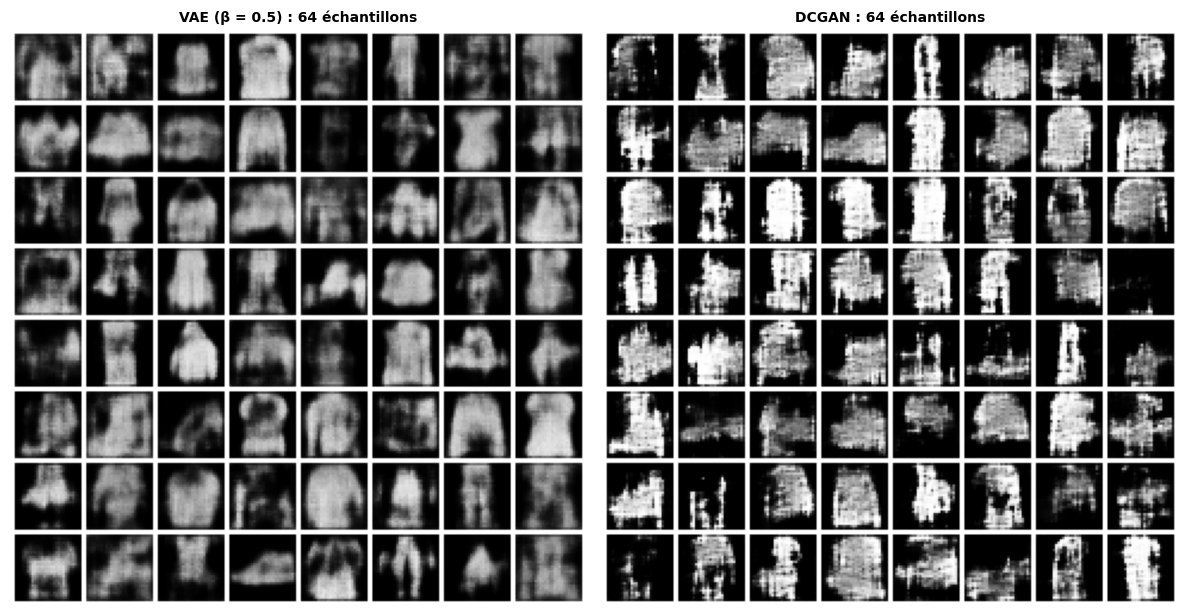

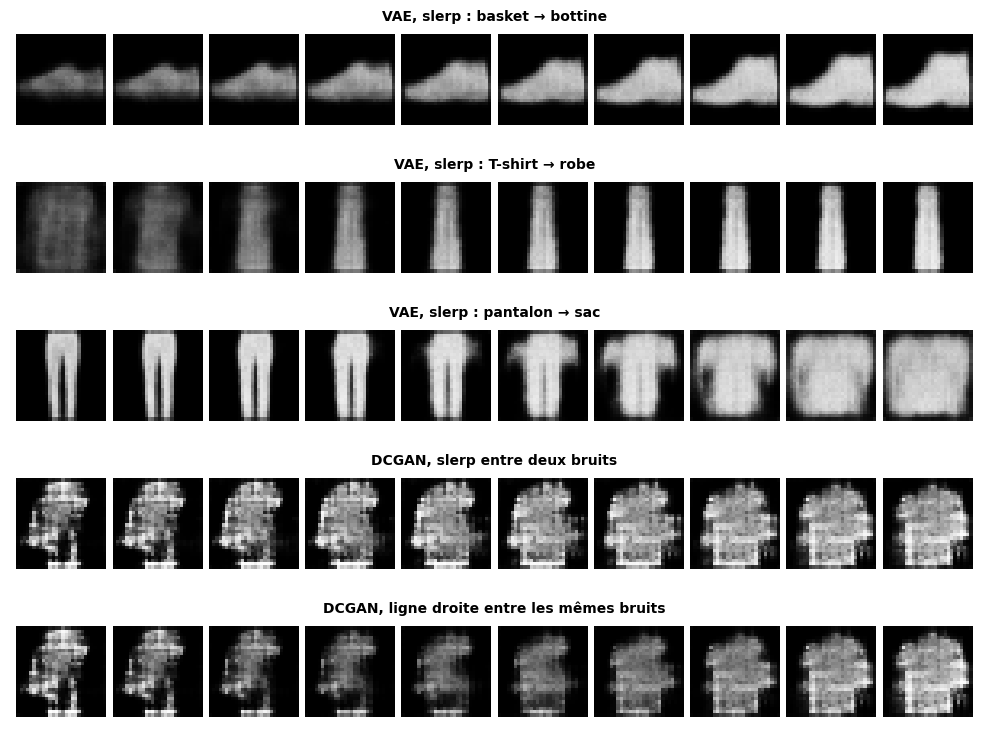

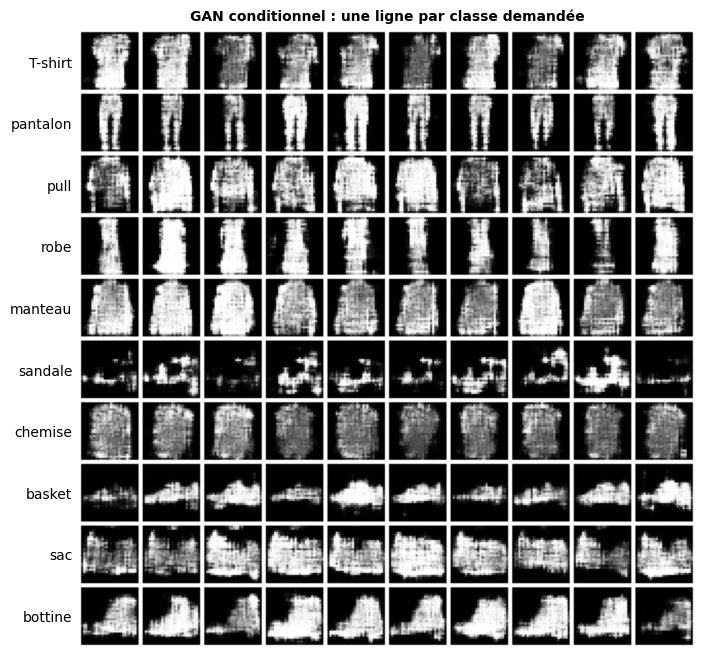

In [21]:
checks_of("MP6.6 galerie")
if ready("VAE_MODELS", "GAN_MODELS") and VAE_MODELS and GAN_MODELS and kit_ok():
    with attempt("MP6.6"):
        seed = CONFIG["seeds"][0]
        vae_0, gan_0 = VAE_MODELS[seed], GAN_MODELS[seed]
        fig, (ax_v, ax_g) = plt.subplots(1, 2, figsize=(12, 6.4))
        show_grid(ax_v, genbench.sample_images(vae_0, 64, seed=SAMPLE_SEED), 8, f"VAE (β = {BETA}) : 64 échantillons")
        show_grid(ax_g, genbench.sample_images(gan_0, 64, seed=SAMPLE_SEED), 8, "DCGAN : 64 échantillons")
        fig.tight_layout()
        save(fig, "galerie.png")
        plt.show()
        pairs = [(int(torch.where(y_val_t == a)[0][0]), int(torch.where(y_val_t == b)[0][0])) for a, b in ((7, 9), (0, 3), (1, 8))]
        rows, titles = [], []
        with torch.no_grad():
            for i, j in pairs:
                mu_ij, _ = vae_0.eval().encode(X_val_t[[i, j]])
                rows.append(genbench.interpolate(vae_0, mu_ij[0].cpu(), mu_ij[1].cpu(), 10))
                titles.append(f"VAE, slerp : {data.CLASSES_FR[y_val[i]]} → {data.CLASSES_FR[y_val[j]]}")
        z_a = torch.randn(2, CONFIG["gan"]["latent_dim"], generator=torch.Generator().manual_seed(SAMPLE_SEED + 1))
        rows.append(genbench.interpolate(gan_0, z_a[0], z_a[1], 10))
        titles.append("DCGAN, slerp entre deux bruits")
        rows.append(genbench.interpolate(gan_0, z_a[0], z_a[1], 10, method="linear"))
        titles.append("DCGAN, ligne droite entre les mêmes bruits")
        fig, axes = plt.subplots(len(rows), 1, figsize=(10, 1.45 * len(rows) + 0.4))
        for ax, row, title in zip(axes, rows, titles):
            show_grid(ax, row, 10, title)
        fig.tight_layout()
        save(fig, "interpolations.png")
        plt.show()
        if CGAN is not None:
            labels_c = torch.arange(10).repeat_interleave(10)
            fig, ax = plt.subplots(figsize=(8, 8.6))
            show_grid(ax, genbench.sample_images(CGAN, 100, seed=SAMPLE_SEED, labels=labels_c), 10,
                      "GAN conditionnel : une ligne par classe demandée")
            for k, name in enumerate(data.CLASSES_FR):
                ax.text(-3, 2 + 30 * k + 14, name, ha="right", va="center", fontsize=10)
            save(fig, "conditionnel.png")
            plt.show()
checks_done()

✍️ **Observations (MP6.6)**

- **La galerie** : les échantillons du VAE sont reconnaissables mais flous, sans texture ni détail (des chemises et des pulls en aplats) ; ceux du DCGAN sont nets, avec des textures et des contrastes, mais certains sont déformés (des sandales en morceaux, des silhouettes aux bords déchirés). Le GAN conditionnel dessine la classe demandée presque à chaque fois ; les sandales, les formes les plus fines, sont ses images les moins réussies.
- **Les interpolations** : entre deux vraies images, le VAE passe d'un vêtement à l'autre par des formes plausibles mais floues (une basket qui monte en bottine) ; entre un pantalon et un sac, le milieu n'est ni l'un ni l'autre. Pour le DCGAN, en dimension 64, le slerp et la ligne droite donnent presque les mêmes images en mode complet ; en mode rapide, le milieu de la ligne droite est plus terne : la norme d'un point au milieu de deux bruits presque orthogonaux tombe à 1/√2 environ, là où le générateur a rarement vu de bruit pendant l'entraînement.

## MP6.7 · README, model card, tests pytest et nettoyage du dépôt ⏱️ 75 min

**Objectif :** un dépôt qu'un recruteur comprend en deux minutes, dont les résultats se reproduisent, et dont les tests attrapent des erreurs.

a) Complète `test_genbench.py` : **au moins trois tests** (un est donné), chacun avec un nom clair et un message dont la première ligne dit ce qui était attendu. La vérification les relance contre cinq **mutants** de `genbench` (une erreur glissée dans `vae_loss`, `gan_step`, `classifier_features`, `nearest_neighbors` ou `load_checkpoint`) : de bons tests en attrapent au moins deux.
b) Termine le `README.md` de portfolio (les résultats chiffrés de `results.json`, la galerie légendée, les limites, la reproduction en une commande : `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=3600 mon_travail/projets/partie_6_generatif/mp6_generatif.ipynb`, précédée de `WB_FAST_MODE=0` pour le mode complet) et la fiche modèle `MODEL_CARD.md` (usage prévu, données, métriques, limites, risques et usages responsables) : leurs modèles sont dans ton dossier.
c) Nettoie : relance tout le notebook de zéro (*Exécution → Tout exécuter*), en mode complet sur Colab si tu peux (🚀), vérifie que le `.gitignore` du projet écarte `runs/` (des checkpoints lourds), puis commite le projet. Le modèle de README pointe vers les figures du mode complet ; si tu n'as que le mode rapide, remplace les liens par les fichiers `…_rapide.png` et dis-le dans le README.

In [22]:
checks_of("MP6.7")
if kit_ok():
    passed, failed, reasons = run_project_tests()
    names_found = set(re.findall(r"def (test_\w+)", (PROJECT / "test_genbench.py").read_text(encoding="utf-8")))
    waiting = [reason for reason in reasons if reason.startswith(PENDING)]
    if waiting:
        pending("MP6.7", f"{len(waiting)} test(s) attendent une fonction de genbench pas encore écrite ; les mutants "
                "attendront que tes tests passent.")
    elif len(names_found) < 3:
        pending("MP6.7", f"test_genbench.py n'a que {len(names_found)} test(s) : écris-en au moins trois.")
    else:
        verdict("MP6.7", failed == 0 and passed >= 3, f"{passed} tests passent.",
                f"{passed} test(s) passe(nt) et {failed} échoue(nt) : il en faut au moins trois, tous verts.")
        if failed == 0 and passed:
            caught = []
            with tempfile.TemporaryDirectory() as folder:
                folder = Path(folder)
                for name, (what, *_) in MUTANTS.items():
                    mutant_plugin(folder, name)
                    _, m_failed, _ = run_project_tests(["-p", f"mutant_{name}"], quiet=True,
                                                       env={"PYTHONPATH": os.pathsep.join([str(folder), os.environ.get("PYTHONPATH", "")])})
                    caught.append(m_failed > 0)
                    print(f"   {'attrapé' if m_failed else 'PAS attrapé'} : {what} ({m_failed} test(s) en échec)")
            verdict("MP6.7", sum(caught) >= 2, f"tes tests attrapent {sum(caught)} mutants sur {len(caught)}.",
                    f"tes tests n'attrapent que {sum(caught)} mutant(s) sur {len(caught)} : teste ce que l'entraînement ne "
                    "montre pas (l'échelle de la loss du VAE, le sens du pas de G, le mode d'évaluation, des distances "
                    "comparées à NumPy, une reprise au bit près).")
    fast_only = []                      # the deliverables that only exist in fast mode (accepted, with an ℹ️ line)
    for name in ("config.json", "results.json"):
        fast_name = name.replace(".json", "_rapide.json")
        if (PROJECT / name).exists():
            verdict("MP6.7", True, f"{name} (mode complet) est livré.", "")
        elif (PROJECT / fast_name).exists():
            fast_only.append(fast_name)
        else:
            pending("MP6.7", f"{name} n'existe pas encore : les étapes MP6.1 et MP6.5 l'écrivent ({fast_name} en mode rapide).")
    readme = check_document("MP6.7", PROJECT / "README.md",
                            {"L'objectif": ["objectif", "goal"], "Le protocole d'évaluation": ["protocole", "protocol"],
                             "Les résultats": ["résultat", "result"], "La galerie": ["galerie", "gallery"],
                             "Les limites": ["limite", "limitation"], "Reproduire": ["reprodui", "reproduc"],
                             "Ce que j'ai appris": ["appris", "learn"]})
    check_document("MP6.7", PROJECT / "MODEL_CARD.md",
                   {"Usage prévu": ["usage", "intended"], "Données": ["donnée", "data"], "Métriques": ["métrique", "metric"],
                    "Limites et risques": ["limite", "risk"]})
    for figure, made_by in (("donnees.png", "MP6.1"), ("vae_beta_courbes.png", "MP6.3"), ("vae_beta_echantillons.png", "MP6.3"),
                            ("gan_courbes.png", "MP6.4"), ("gan_progression.png", "MP6.4"), ("frechet.png", "MP6.5"),
                            ("classes.png", "MP6.5"), ("voisins.png", "MP6.5"), ("galerie.png", "MP6.6"),
                            ("interpolations.png", "MP6.6")):
        fast_figure = figure.replace(".png", "_rapide.png")
        if (FIGURES / figure).exists():
            shown = figure
        elif (FIGURES / fast_figure).exists():
            shown = fast_figure
            fast_only.append(f"figures/{fast_figure}")
        else:
            pending("MP6.7", f"figures/{figure} n'existe pas encore : l'étape {made_by} la crée ({fast_figure} en mode rapide).")
            continue
        if readme:
            verdict("MP6.7", f"figures/{figure}" in readme or f"figures/{fast_figure}" in readme,
                    f"le README montre figures/{shown if f'figures/{shown}' in readme else figure}.",
                    f"le README doit montrer figures/{shown}, avec sa légende (le modèle pointe vers les figures du mode "
                    "complet : sans mode complet, mets les liens vers les fichiers « _rapide »).")
    if fast_only:
        print(f"ℹ️ MP6.7 : livrés en mode rapide seulement : {', '.join(fast_only)}. C'est accepté (cahier des charges, "
              "« Les deux modes et la note ») ; le mode complet sur Colab donnera de meilleures images et des mesures sur "
              "10 000 images, à reporter dans le README si tu le lances.")
    gitignore = PROJECT / ".gitignore"
    ignored = gitignore.exists() and re.search(r"(?m)^/?runs/?\s*$", gitignore.read_text(encoding="utf-8"))
    verdict("MP6.7", bool(ignored), "le .gitignore du projet écarte runs/ (les checkpoints du GAN).",
            "le dossier du projet doit avoir son propre .gitignore avec une ligne « runs/ » : les checkpoints sont lourds "
            "et se régénèrent, et le projet doit rester propre quand tu le copies dans un dépôt de portfolio.")
    print(f"\n⏱️ notebook exécuté en {(time.perf_counter() - STARTED) / 60:.1f} min ({'mode rapide' if FAST_MODE else 'mode complet'})")
checks_done()

pytest: 19 passed in 2.21s
✅ MP6.7 : 19 tests passent.


   attrapé : vae_loss moyenne la reconstruction sur les pixels au lieu de la sommer (1 test(s) en échec)


   attrapé : gan_step entraîne G avec le label « faux » : il apprend à être repéré (1 test(s) en échec)


   attrapé : classifier_features laisse le classifieur en mode entraînement (batchnorm et dropout) (1 test(s) en échec)


   attrapé : nearest_neighbors rend les distances au carré (1 test(s) en échec)


   attrapé : load_checkpoint ne restaure pas l'état du générateur aléatoire : la reprise tire d'autres mini-batches (2 test(s) en échec)
✅ MP6.7 : tes tests attrapent 5 mutants sur 5.
✅ MP6.7 : config.json (mode complet) est livré.
✅ MP6.7 : results.json (mode complet) est livré.
✅ MP6.7 : README.md existe.
✅ MP6.7 : README.md : section « L'objectif ».
✅ MP6.7 : README.md : section « Le protocole d'évaluation ».
✅ MP6.7 : README.md : section « Les résultats ».
✅ MP6.7 : README.md : section « La galerie ».
✅ MP6.7 : README.md : section « Les limites ».
✅ MP6.7 : README.md : section « Reproduire ».
✅ MP6.7 : README.md : section « Ce que j'ai appris ».
✅ MP6.7 : README.md : plus aucun paragraphe « TODO ».
✅ MP6.7 : MODEL_CARD.md existe.
✅ MP6.7 : MODEL_CARD.md : section « Usage prévu ».
✅ MP6.7 : MODEL_CARD.md : section « Données ».
✅ MP6.7 : MODEL_CARD.md : section « Métriques ».
✅ MP6.7 : MODEL_CARD.md : section « Limites et risques ».
✅ MP6.7 : MODEL_CARD.md : plus aucun paragraphe « T

## ✅ Bilan

**Grille d'évaluation** (sur 20, détaillée dans le cahier des charges) : reproductibilité : graines, configuration, notebook exécutable de bout en bout (3) · VAE correct et analysé : courbes, choix de β justifié (4) · GAN entraîné de façon stable, journalisé et repris depuis un checkpoint (4) · évaluation rigoureuse : protocole fixé à l'avance, plusieurs graines, effondrement de mode et mémorisation vérifiés (4) · galerie claire et légendée (2) · README et model card : résultats chiffrés, limites, usages responsables (3).

**Pour aller plus loin** : les extensions du cahier des charges (une petite diffusion dans l'espace latent du VAE, préparation du bonus B5 ; la distance de Fréchet sur deux extracteurs de features ; une démo Gradio sur un Space Hugging Face ; un agent de morpion en self-play). La suite du workbook : les chapitres bonus, dont B5 (diffusion), qui comparera un modèle de diffusion à ces deux générateurs avec ta distance de Fréchet.